In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

nist_spectra_df = pd.read_pickle('../../data/proc/nist20/spec_df.pkl')
nist_spectra_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,nce,prec_mz,peaks,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ce_type
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,NaN,1467.0061,"[(45.96, 46.35), (597.48, 51.85), (598.5, 41.3...",NaN,0,NaN,NaN,NaN,NaN,single
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,NaN,1467.0061,"[(597.5, 50.95), (599.5, 683.32), (1449.98, 99...",NaN,0,NaN,NaN,NaN,NaN,single
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,...,NaN,1467.0061,"[(537.39, 55.94), (599.5, 999.0), (600.51, 42....",NaN,0,NaN,NaN,NaN,NaN,single
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,...,NaN,1467.0061,"[(597.46, 41.86), (598.5, 45.15), (599.51, 999...",NaN,0,NaN,NaN,NaN,NaN,single
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,...,NaN,1467.0061,"[(598.49, 47.85), (599.5, 999.0), (600.5, 85.5...",NaN,0,NaN,NaN,NaN,NaN,single


In [2]:
prec_types = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+K]+', '[M+NH4]+']
nist_spectra_df = nist_spectra_df[nist_spectra_df['prec_type'].isin(prec_types)]
# Focus on nist20_hr only — MoNA23 [M+K]+/[M+Na]+ are poorly isolated chimeric spectra
# (MoNA23 [M+K]+ p50=536 raw peaks vs nist20_hr p50=10; MoNA23 [M+Na]+ p50=380 vs 13)
nist_spectra_df = nist_spectra_df[nist_spectra_df['dset'] == 'nist20_hr']
print('dset counts:', nist_spectra_df['dset'].value_counts().to_dict())
print(nist_spectra_df['prec_type'].value_counts())

dset counts: {'nist20_hr': 482762}
prec_type
[M+H]+      311072
[M-H]-      123854
[M+Na]+      38337
[M+NH4]+      8545
[M+K]+         954
Name: count, dtype: int64


In [3]:
nist_mol_df = pd.read_pickle('../../data/proc/nist20/mol_df.pkl')
nist_mol_df.drop(columns=['mol'], inplace=True)
nist_mol_df.head()

,smiles,mol_id,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC1=CCN(Cc2ccccc2)CC1,1,PMICKOYXYJSXPC,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-6-8-14(9-7-12)10-11-...,252.155,251.030962,14,15,0,True,0
2,BrC1CCCCCC(Br)C12OCCO2,2,OQCIVOUQHXUSEL,C1CCCC2(CCC1)OCCO2,C10H16Br2O2,InChI=1S/C10H16Br2O2/c11-8-4-2-1-3-5-9(12)10(8...,328.044,325.951704,14,15,0,True,0
3,BrC1CCN(Cc2ccccc2)C1,3,VOXJTPBOJBQGSL,c1ccc(CN2CCCC2)cc1,C11H14BrN,InChI=1S/C11H14BrN/c12-11-6-7-13(9-11)8-10-4-2...,240.144,239.030962,13,14,0,True,0
4,BrC=C(c1ccccc1)c1ccccc1,4,QRDVTIMUEDYLOC,C=C(c1ccccc1)c1ccccc1,C14H11Br,InChI=1S/C14H11Br/c15-11-14(12-7-3-1-4-8-12)13...,259.146,258.004412,15,16,0,True,0


In [4]:
ace_max = 50
nce_max = 70
print(f"ACE max: {ace_max}, NCE max: {nce_max}")
print(f"Before filtering: {len(nist_spectra_df)} spectra")
# Filter FT by NCE (native unit) and QTOF by ACE (native unit) separately
# OR condition on ace+nce was wrong: FT HCD spectra with NCE>70 leaked through via ace<=50
ft_mask = (nist_spectra_df["inst_type"] == "FT") & (nist_spectra_df["nce"] <= nce_max)
qtof_mask = (nist_spectra_df["inst_type"] == "QTOF") & (nist_spectra_df["ace"] <= ace_max)
nist_spectra_df = nist_spectra_df[ft_mask | qtof_mask]
print(f"After filtering: {len(nist_spectra_df)} spectra")
print(nist_spectra_df["prec_type"].value_counts())
nist_spectra_df.loc[:, "ace"] = nist_spectra_df.apply(lambda x: round(x["prec_mz"] * x["nce"] / 500 if pd.isnull(x["ace"]) else x["ace"], 0), axis=1)
nist_spectra_df.loc[:, "nce"] = nist_spectra_df.apply(lambda x: round(x["ace"] * 500 / x["prec_mz"] if pd.isnull(x["nce"]) else x["nce"], 0), axis=1)

ACE max: 50, NCE max: 70
Before filtering: 482762 spectra
After filtering: 343689 spectra
prec_type
[M+H]+      213348
[M-H]-       88860
[M+Na]+      33812
[M+NH4]+      6795
[M+K]+         874
Name: count, dtype: int64


In [5]:
nist_spectra_df = nist_spectra_df.merge(nist_mol_df, on='mol_id', how='inner')

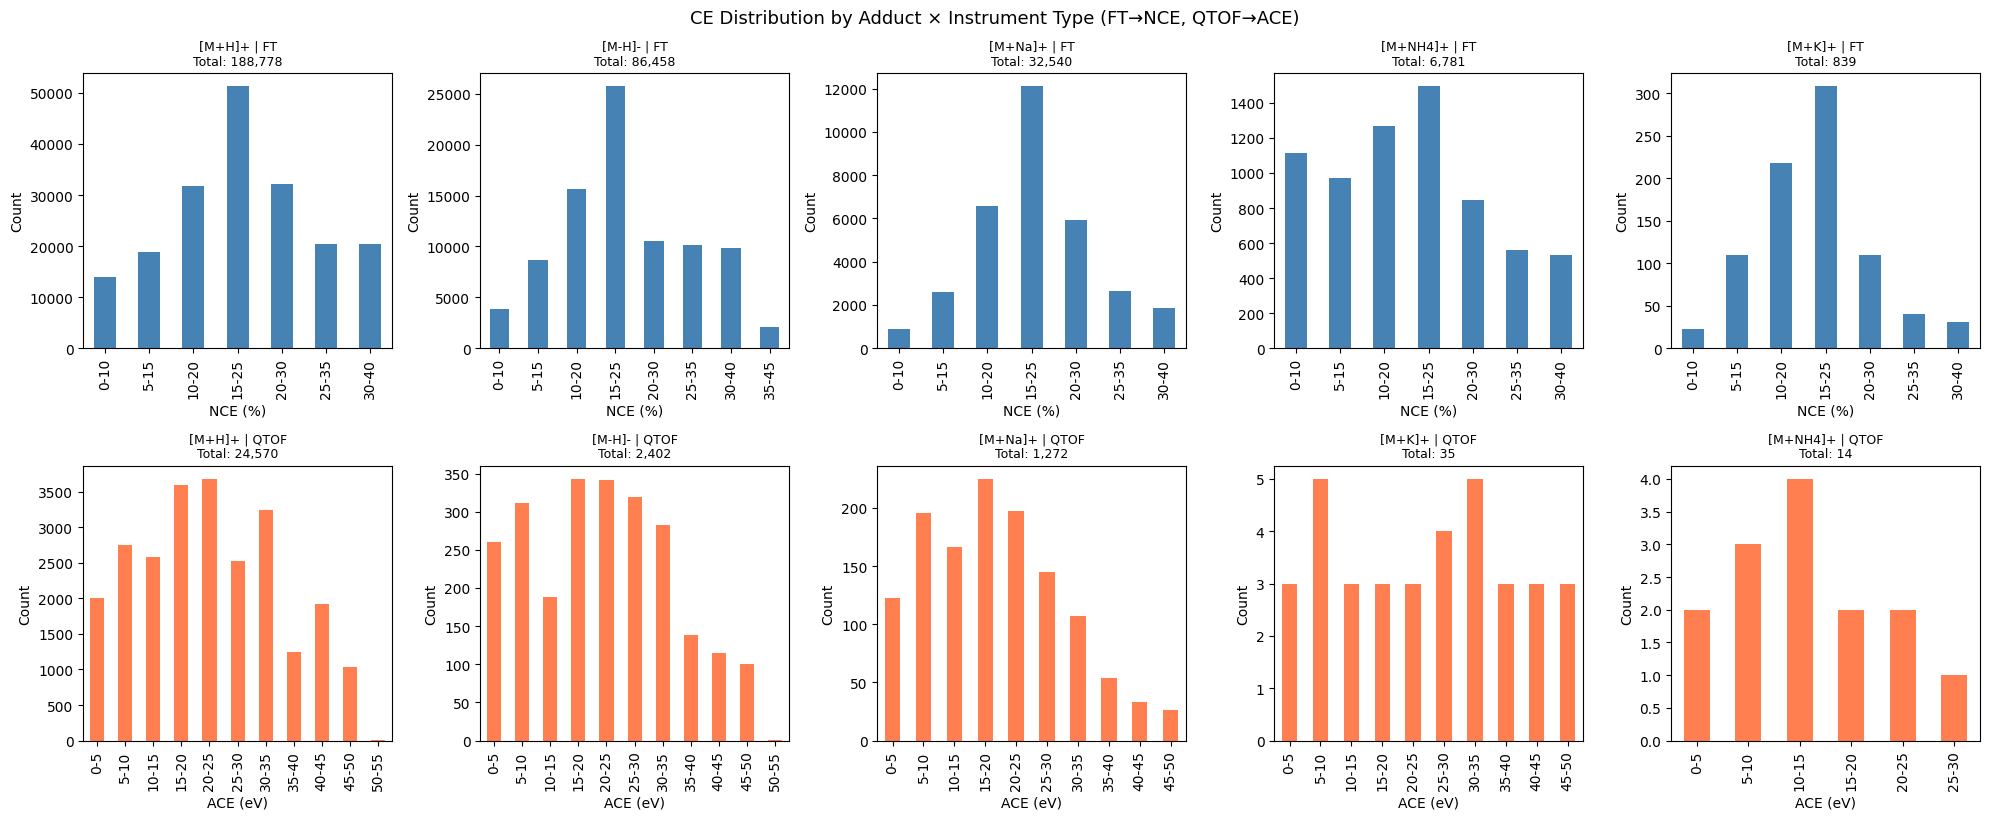

In [6]:
# CE distribution per adduct × instrument type: FT (row 1) → NCE, QTOF (row 2) → ACE
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 70, 5)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}
colors = {'FT': 'steelblue', 'QTOF': 'coral'}

combo_counts = (
    nist_spectra_df
    .groupby(['prec_type', 'inst_type'])
    .size()
    .sort_values(ascending=False)
)

ft_combos   = [(pt, it) for pt, it in combo_counts.index if it == 'FT']
qtof_combos = [(pt, it) for pt, it in combo_counts.index if it == 'QTOF']
ncols = max(len(ft_combos), len(qtof_combos), 1)

fig, axes = plt.subplots(2, ncols, figsize=(ncols * 4, 8), sharey=False)

for row, (inst_type, combos) in enumerate([('FT', ft_combos), ('QTOF', qtof_combos)]):
    ce_col, ce_label, bin_size, bin_starts = inst_ce_cfg[inst_type]
    bins = list(bin_starts)
    bin_labels = [f"{b}-{b + bin_size}" for b in bins[:-1]]

    for col, (prec_type, _) in enumerate(combos):
        ce_vals = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            ce_col,
        ].dropna()

        binned_data = {lbl: 0 for lbl in bin_labels}
        for val in ce_vals:
            idx = int((val - bins[0]) // bin_size)
            if 0 <= idx < len(bin_labels):
                binned_data[bin_labels[idx]] += 1

        binned_series = pd.Series(binned_data)
        binned_series = binned_series[binned_series > 0]

        ax = axes[row, col]
        if len(binned_series) > 0:
            binned_series.plot(kind='bar', ax=ax, color=colors[inst_type])
        ax.set_title(f"{prec_type} | {inst_type}\nTotal: {len(ce_vals):,}", fontsize=9)
        ax.set_xlabel(ce_label)
        ax.set_ylabel('Count')
        ax.tick_params(axis='x', rotation=90)

    for col in range(len(combos), ncols):
        axes[row, col].set_visible(False)

plt.tight_layout()
plt.suptitle('CE Distribution by Adduct × Instrument Type (FT→NCE, QTOF→ACE)', fontsize=13, y=1.02)
plt.show()


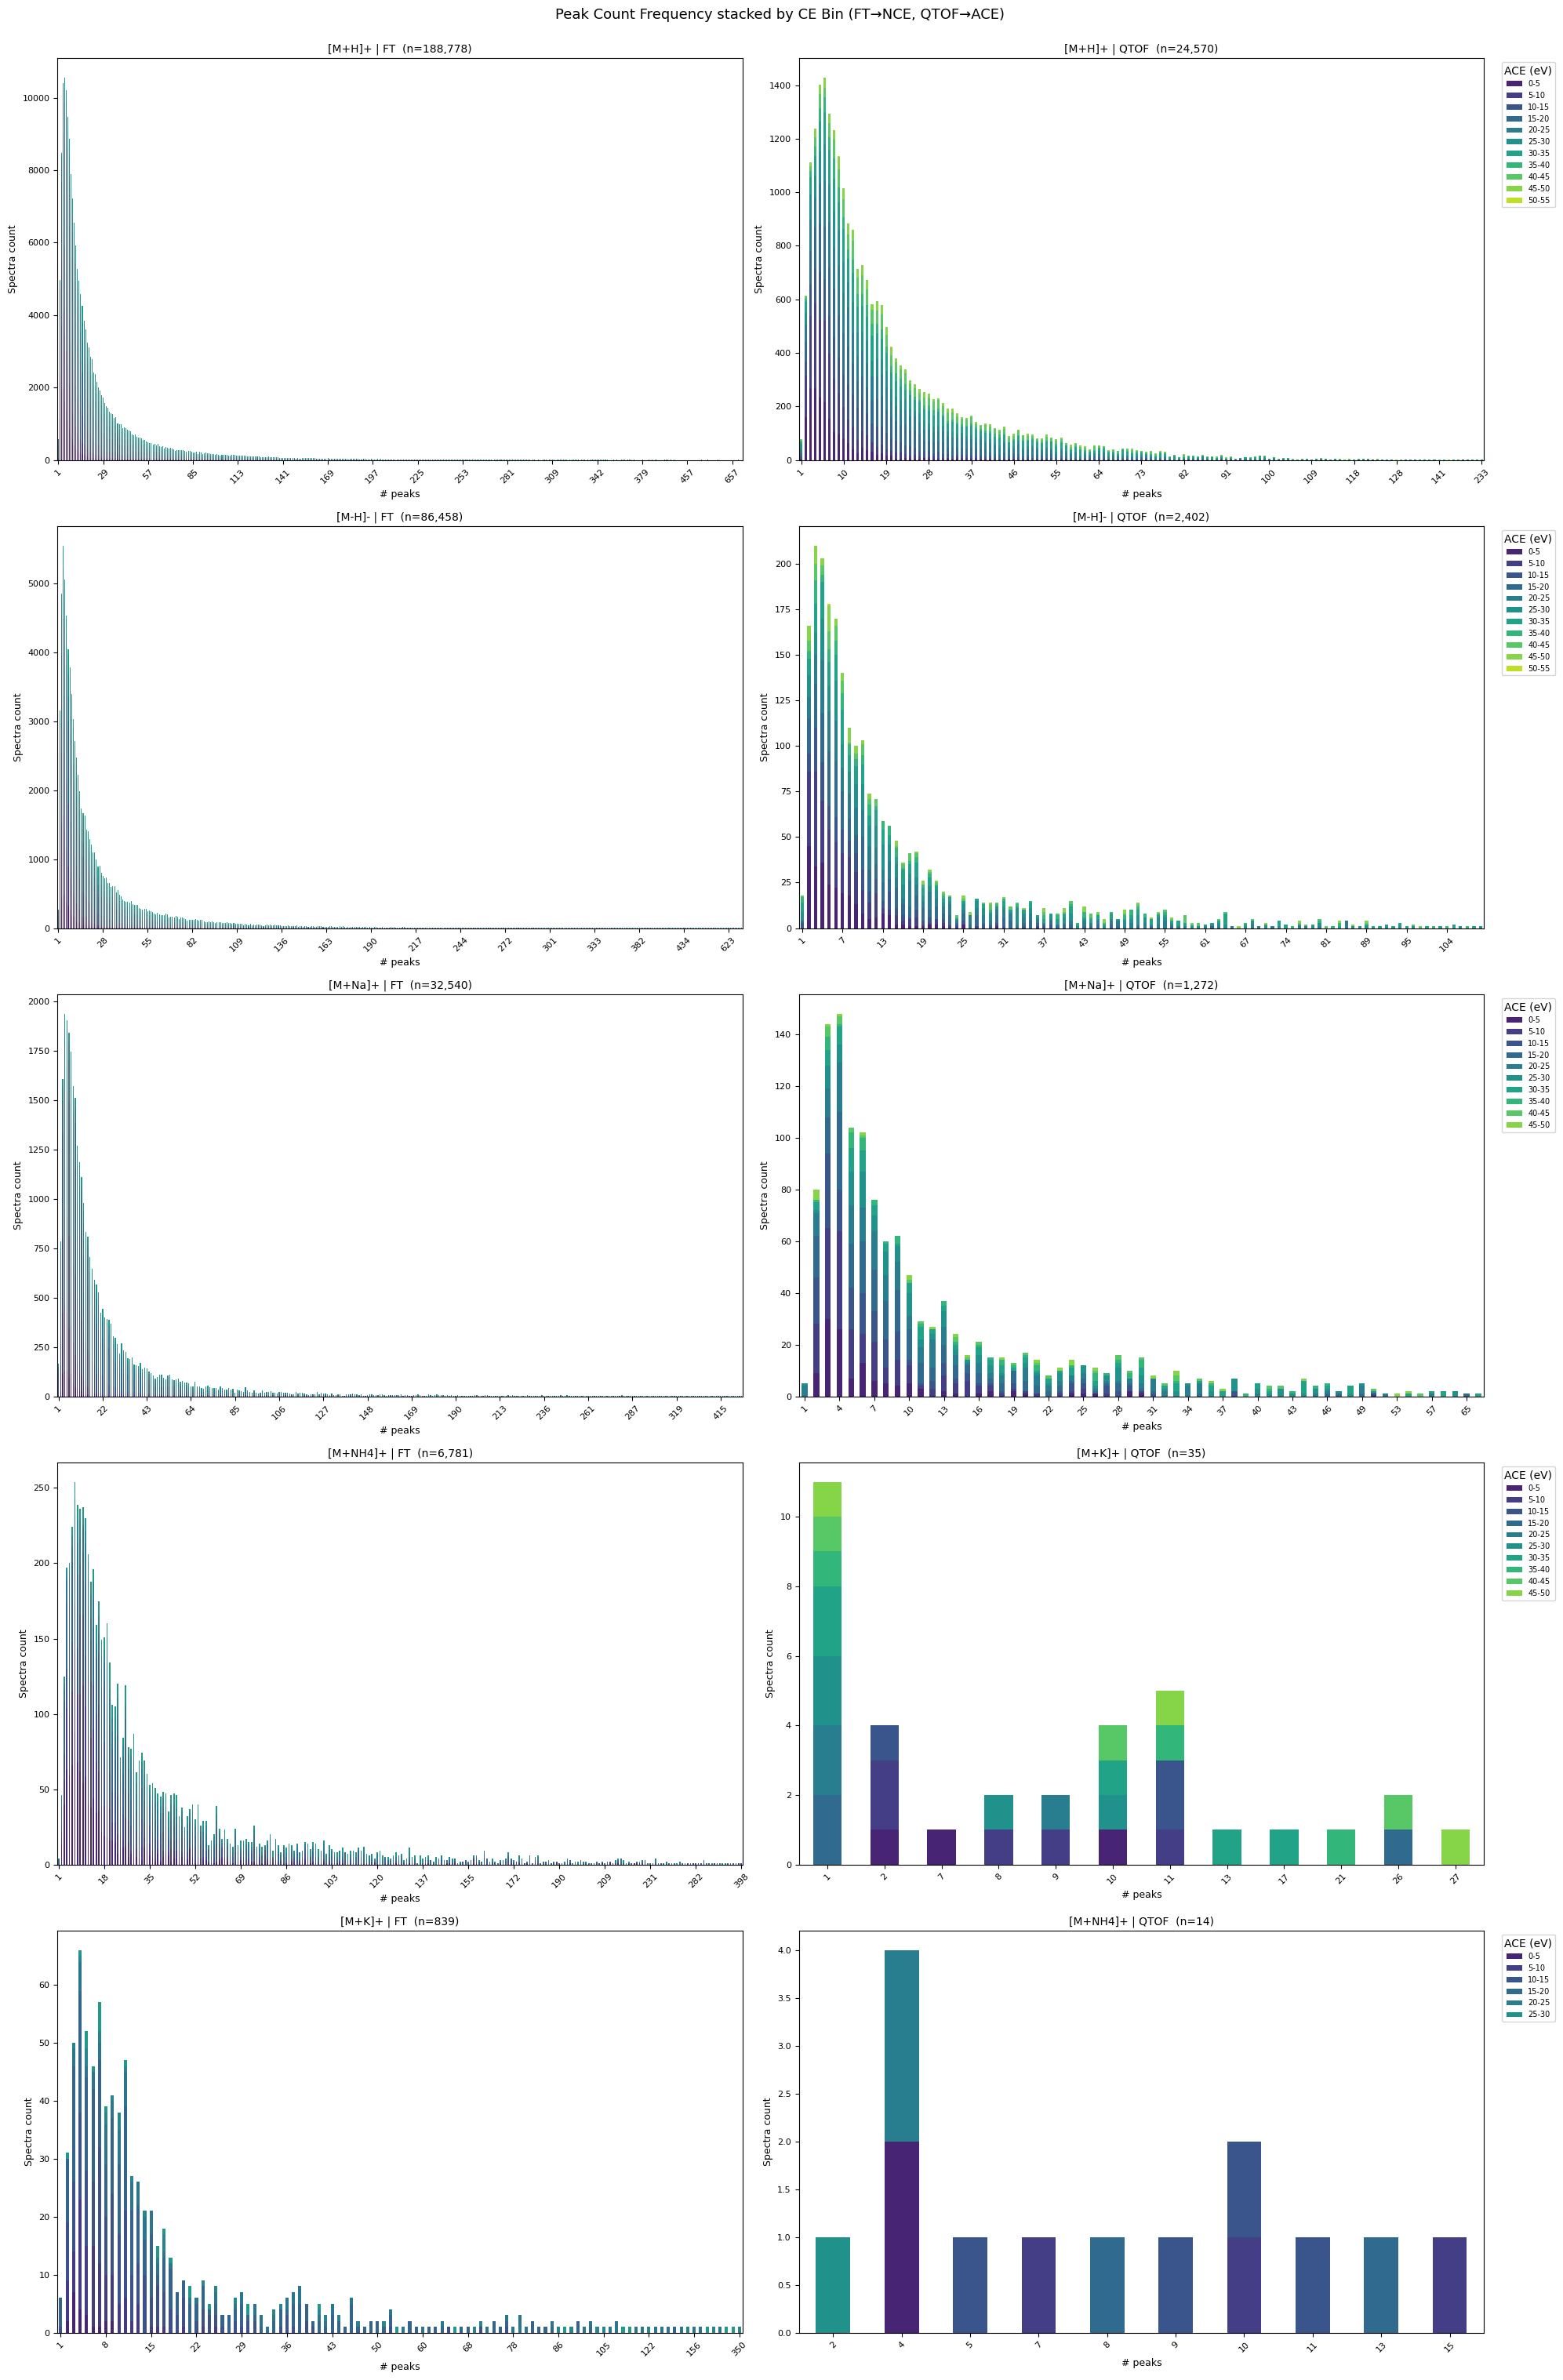

In [7]:
# Peak count frequency: x=raw peak count, stacked by CE bins — FT (row 1) / QTOF (row 2)
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}

if 'num_peaks' not in nist_spectra_df.columns:
    nist_spectra_df['num_peaks'] = nist_spectra_df['peaks'].apply(len)

combo_counts = (
    nist_spectra_df
    .groupby(['prec_type', 'inst_type'])
    .size()
    .sort_values(ascending=False)
)
ft_combos   = [(pt, it) for pt, it in combo_counts.index if it == 'FT']
qtof_combos = [(pt, it) for pt, it in combo_counts.index if it == 'QTOF']
nrows = max(len(ft_combos), len(qtof_combos), 1)

fig, axes = plt.subplots(nrows, 2, figsize=(20, 6 * nrows), sharey=False, squeeze=False)

for col, (inst_type, combos) in enumerate([('FT', ft_combos), ('QTOF', qtof_combos)]):
    ce_col, ce_label, bin_size, bin_starts = inst_ce_cfg[inst_type]
    ce_bins = list(bin_starts)
    ce_bin_labels = [f"{b}-{b + bin_size}" for b in ce_bins[:-1]]
    ce_colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(ce_bin_labels)))

    for row, (prec_type, _) in enumerate(combos):
        df_sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            [ce_col, 'num_peaks'],
        ].dropna(subset=[ce_col]).copy()

        df_sub['ce_bin'] = df_sub[ce_col].apply(
            lambda v: ce_bin_labels[int((v - ce_bins[0]) // bin_size)]
            if 0 <= int((v - ce_bins[0]) // bin_size) < len(ce_bin_labels) else None
        )
        df_sub = df_sub.dropna(subset=['ce_bin'])

        # x = raw num_peaks, stacked = ce_bin
        active_ce = [l for l in ce_bin_labels if (df_sub['ce_bin'] == l).any()]
        pivot = (
            df_sub.groupby(['num_peaks', 'ce_bin'])
            .size()
            .unstack(fill_value=0)
            .reindex(columns=active_ce, fill_value=0)
            .sort_index()
        )

        ax = axes[row, col]
        if len(pivot) > 0:
            pivot.plot(kind='bar', stacked=True, ax=ax,
                       color=ce_colors[:len(active_ce)], legend=(col == 1))
        if col == 1:
            ax.legend(title=ce_label, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7)
        ax.set_title(f"{prec_type} | {inst_type}  (n={len(df_sub):,})", fontsize=10)
        ax.set_xlabel('# peaks', fontsize=9)
        ax.set_ylabel('Spectra count', fontsize=9)
        if len(pivot) > 20:
            step = max(1, len(pivot) // 15)
            ax.set_xticks(range(0, len(pivot), step))
            ax.set_xticklabels(pivot.index[::step])
        ax.tick_params(axis='x', rotation=45, labelsize=8)
        ax.tick_params(axis='y', labelsize=8)

    for row in range(len(combos), nrows):
        axes[row, col].set_visible(False)

plt.tight_layout()
plt.suptitle('Peak Count Frequency stacked by CE Bin (FT→NCE, QTOF→ACE)', fontsize=13, y=1.01)
plt.show()


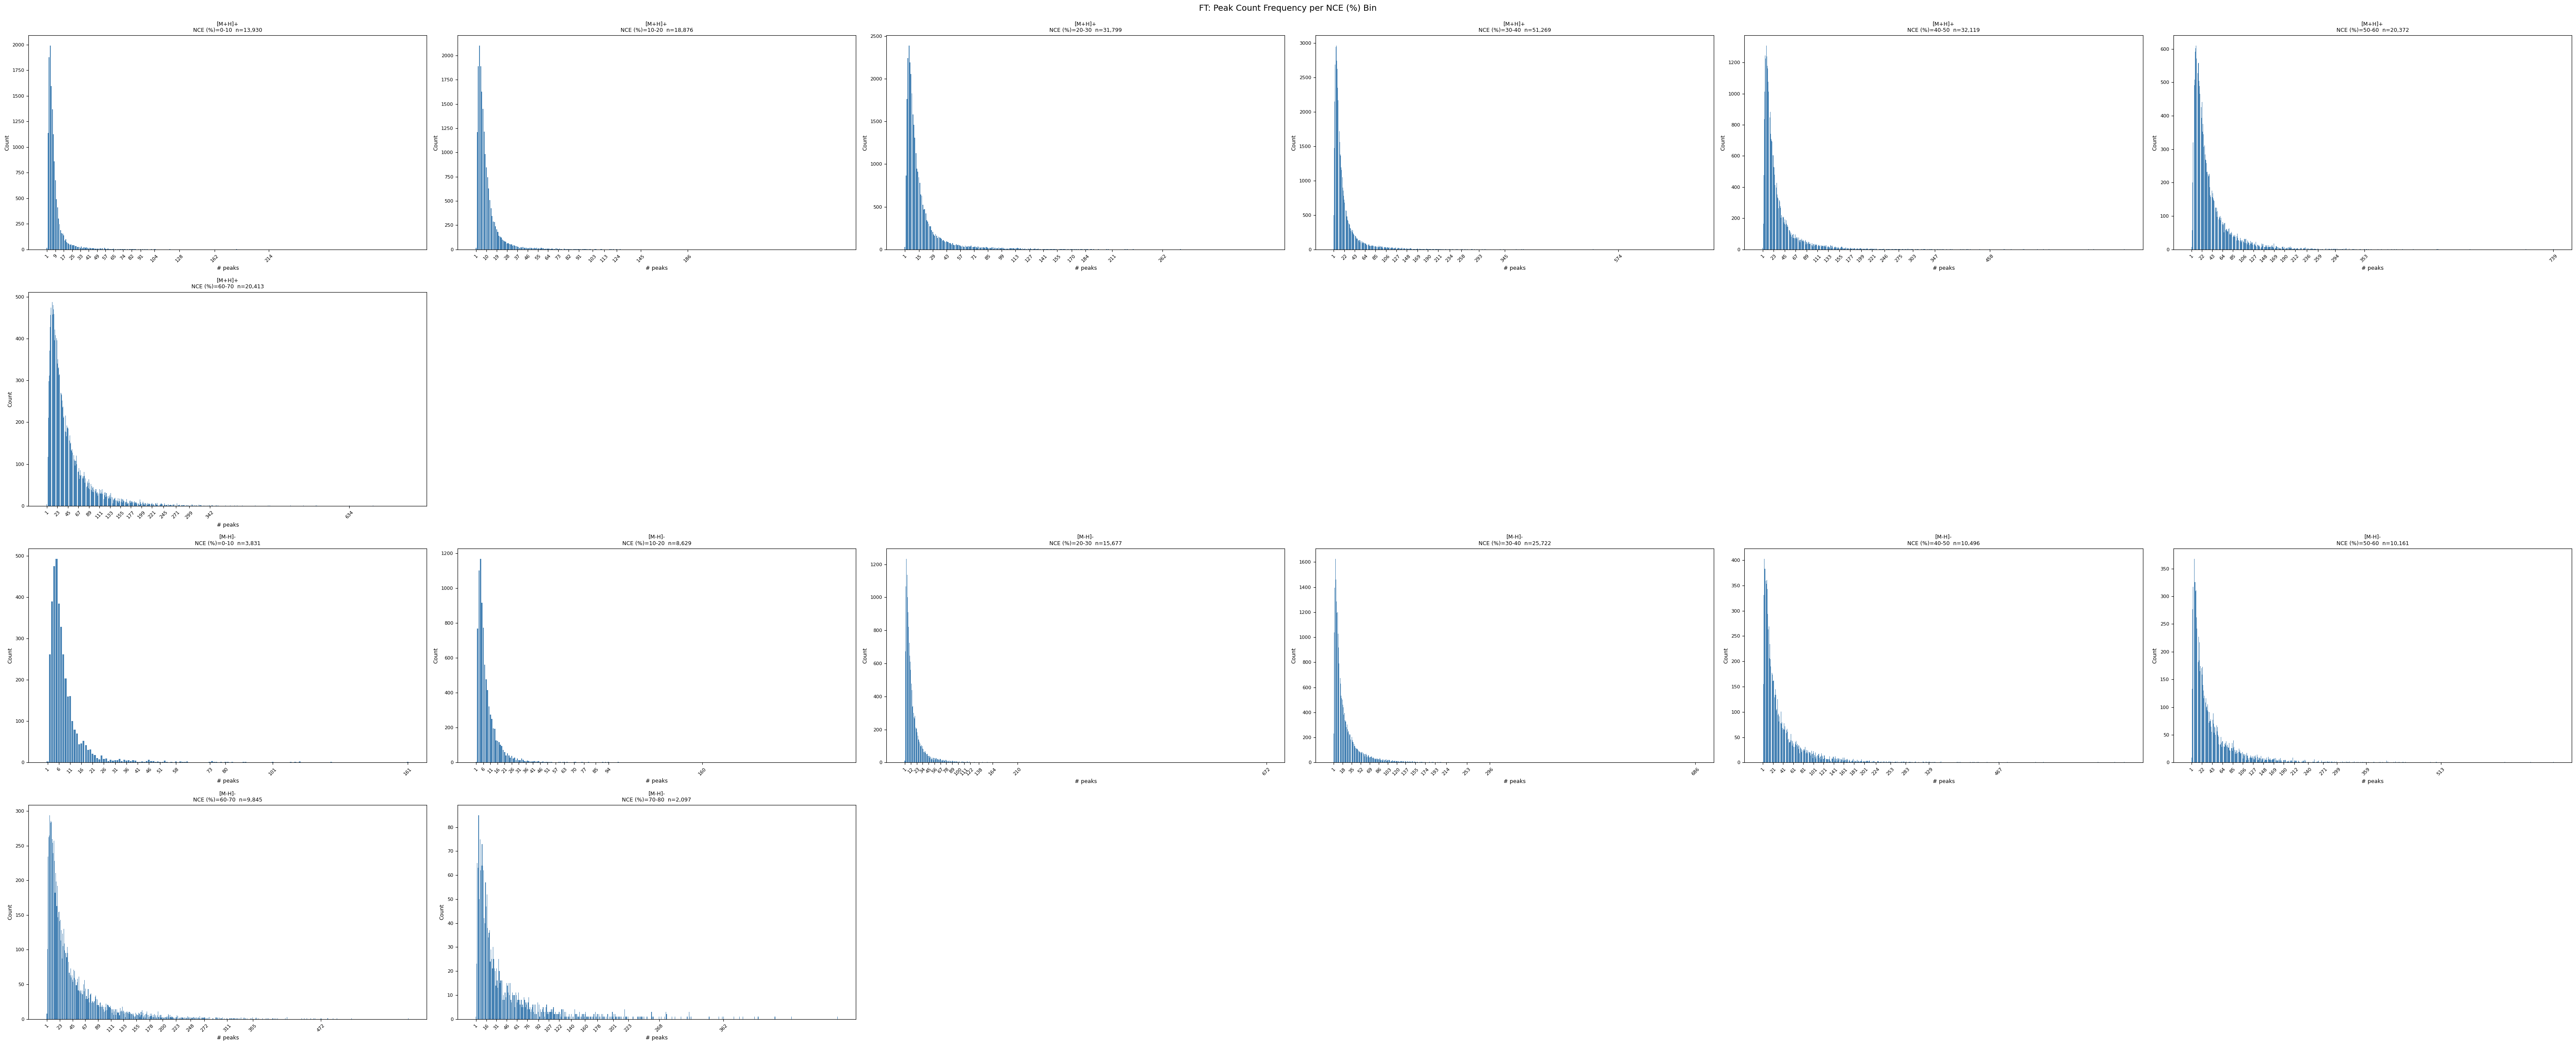

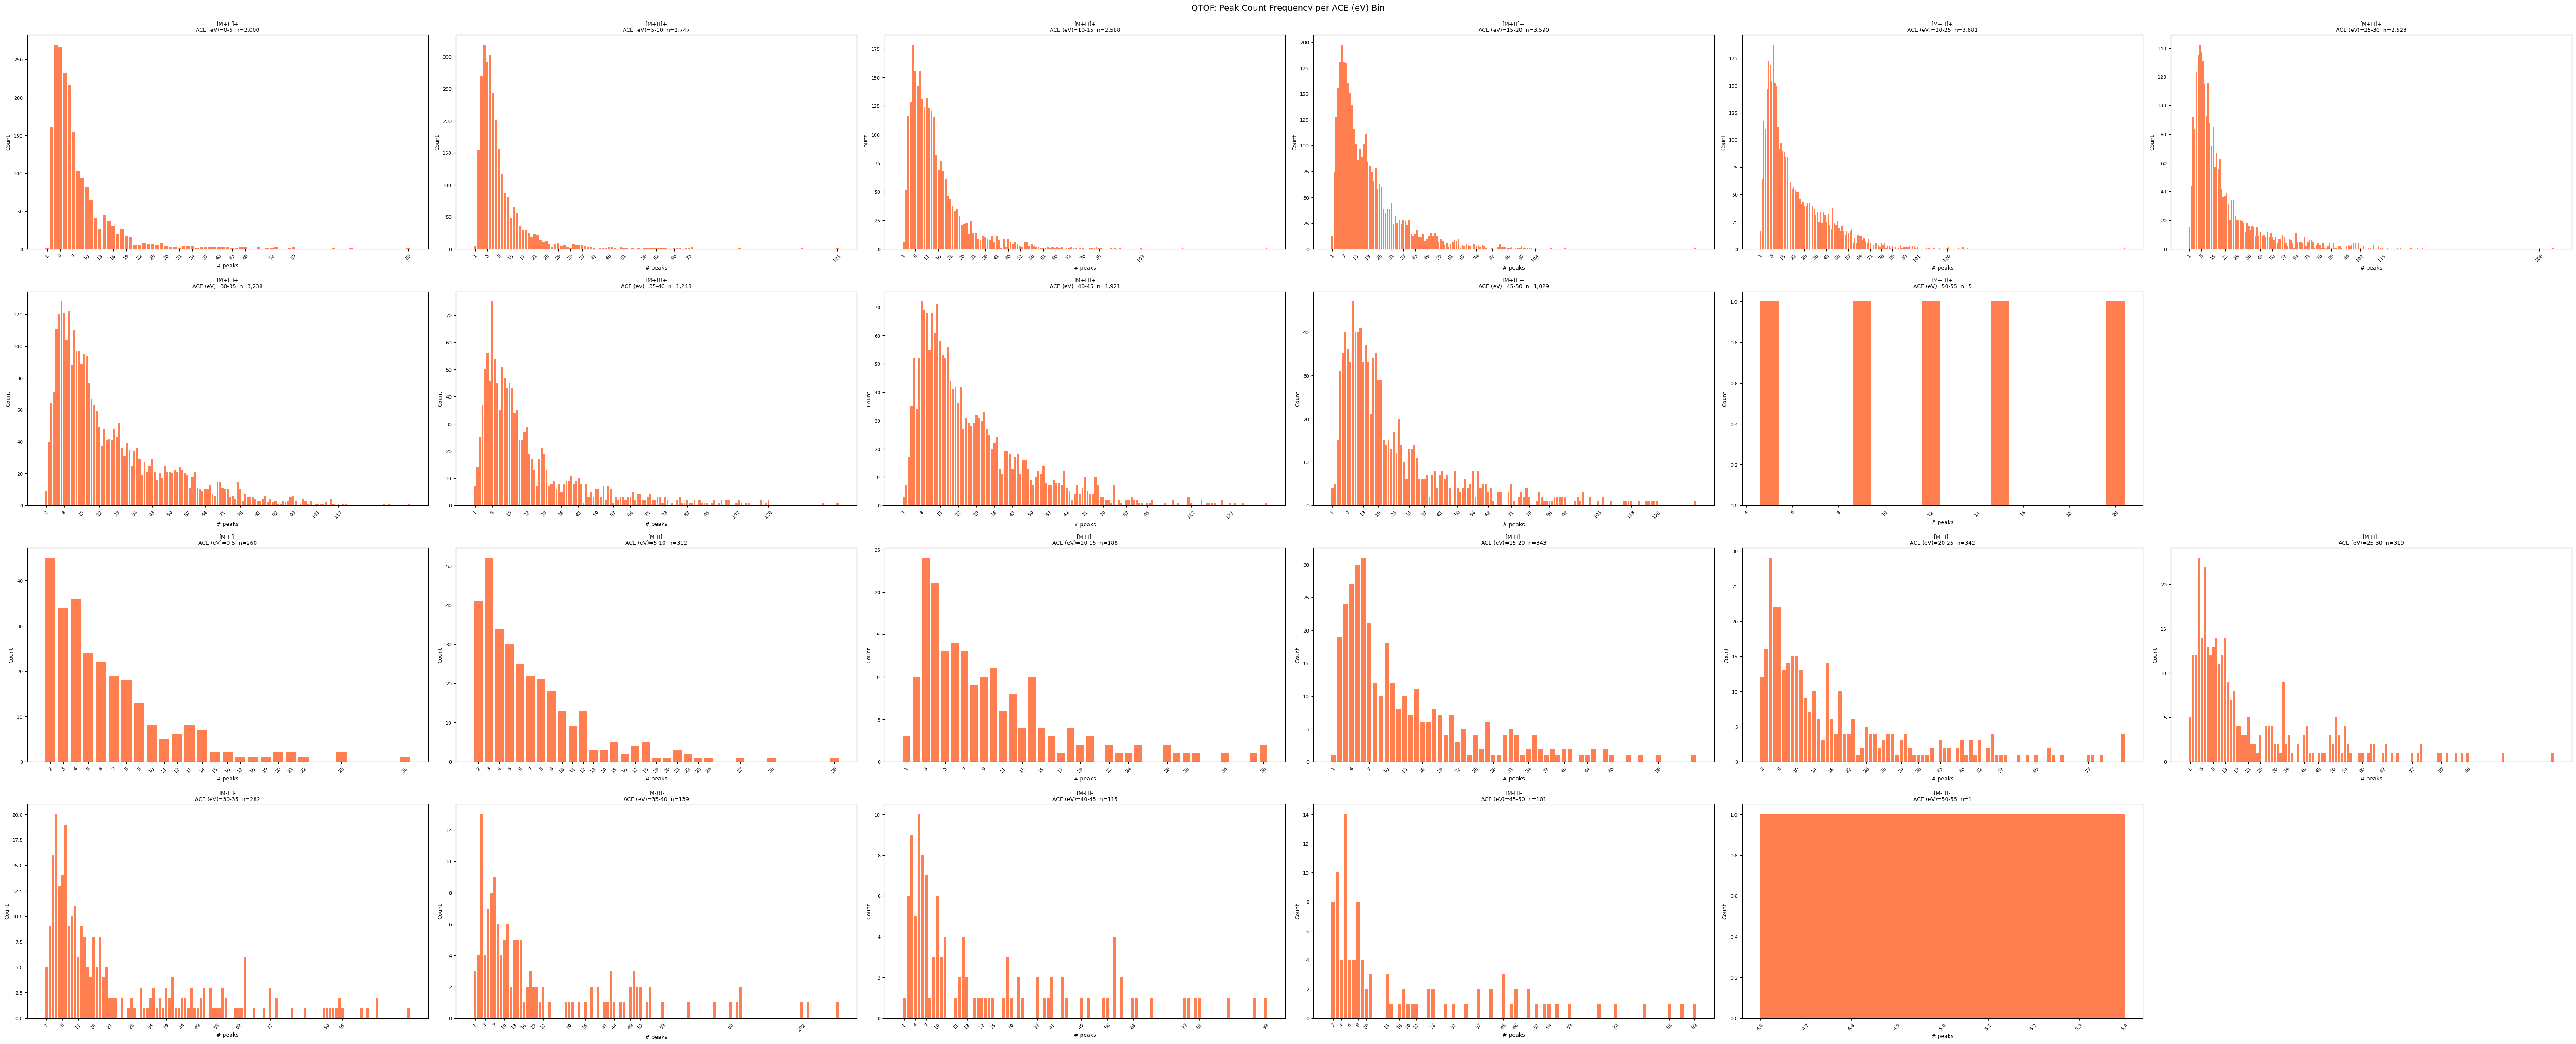

In [8]:
# Peak count frequency per CE bin — raw counts, no binning; FT and QTOF as separate figures
import math

target_adducts = ['[M+H]+', '[M-H]-']
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}
colors = {'FT': 'steelblue', 'QTOF': 'coral'}

if 'num_peaks' not in nist_spectra_df.columns:
    nist_spectra_df['num_peaks'] = nist_spectra_df['peaks'].apply(len)

def assign_ce_bin(df_sub, ce_col, bin_size, ce_bins, ce_bin_labels):
    df_sub = df_sub.dropna(subset=[ce_col]).copy()
    df_sub['ce_bin'] = df_sub[ce_col].apply(
        lambda v: ce_bin_labels[int((v - ce_bins[0]) // bin_size)]
        if 0 <= int((v - ce_bins[0]) // bin_size) < len(ce_bin_labels) else None
    )
    return df_sub.dropna(subset=['ce_bin'])

ncols = 6

for inst_type in ['FT', 'QTOF']:
    ce_col, ce_label, bin_size, bin_starts = inst_ce_cfg[inst_type]
    ce_bins = list(bin_starts)
    ce_bin_labels = [f"{b}-{b + bin_size}" for b in ce_bins[:-1]]

    # Prepare data and active bins per adduct
    adduct_info = []
    for prec_type in target_adducts:
        df_sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            [ce_col, 'num_peaks'],
        ].copy()
        df_sub = assign_ce_bin(df_sub, ce_col, bin_size, ce_bins, ce_bin_labels)
        active_bins = [l for l in ce_bin_labels if (df_sub['ce_bin'] == l).any()]
        adduct_info.append((prec_type, active_bins, df_sub))

    # Compute grid size: each adduct occupies ceil(n_bins / ncols) rows
    adduct_row_offsets = []
    total_rows = 0
    for _, active_bins, _ in adduct_info:
        adduct_row_offsets.append(total_rows)
        total_rows += max(1, math.ceil(len(active_bins) / ncols))

    fig, axes = plt.subplots(total_rows, ncols, figsize=(ncols * 10, total_rows * 6), squeeze=False)

    for (prec_type, active_bins, df_sub), row_offset in zip(adduct_info, adduct_row_offsets):
        for i, ce_bin_lbl in enumerate(active_bins):
            row = row_offset + i // ncols
            col = i % ncols
            freq = (
                df_sub.loc[df_sub['ce_bin'] == ce_bin_lbl, 'num_peaks']
                .value_counts()
                .sort_index()
            )
            ax = axes[row, col]
            ax.bar(freq.index, freq.values, color=colors[inst_type], width=0.8)
            ax.set_title(f"{prec_type}\n{ce_label}={ce_bin_lbl}  n={freq.sum():,}", fontsize=9)
            ax.set_xlabel('# peaks', fontsize=9)
            ax.set_ylabel('Count', fontsize=9)
            # Thin out x ticks if many unique values
            if len(freq) > 20:
                step = max(1, len(freq) // 15)
                ticks = freq.index[::step]
                ax.set_xticks(ticks)
            ax.tick_params(axis='x', rotation=45, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)

        # Hide unused axes in this adduct's rows
        n_rows_used = max(1, math.ceil(len(active_bins) / ncols))
        for i in range(len(active_bins), n_rows_used * ncols):
            axes[row_offset + i // ncols, i % ncols].set_visible(False)

    plt.tight_layout()
    plt.suptitle(f'{inst_type}: Peak Count Frequency per {ce_label} Bin', fontsize=14, y=1.01)
    plt.show()


In [9]:

# Filtered peak count (>1% base peak) — describe by prec_type × inst_type, binned by CE
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}

def filtered_peak_count(peaks):
    if not peaks:
        return 0
    max_int = max(i for _, i in peaks)
    if max_int <= 0:
        return 0
    return sum(1 for _, i in peaks if i > 0.01 * max_int)

nist_spectra_df['filtered_num_peaks'] = nist_spectra_df['peaks'].apply(filtered_peak_count)

target_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+K]+']

records = []
for inst_type, (ce_col, ce_label, bin_size, bin_starts) in inst_ce_cfg.items():
    ce_bins = list(bin_starts)
    ce_bin_labels = [f"{b}-{b+bin_size}" for b in ce_bins[:-1]]

    for prec_type in target_adducts:
        df_sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            [ce_col, 'filtered_num_peaks'],
        ].dropna(subset=[ce_col]).copy()

        if len(df_sub) == 0:
            continue

        # Overall row for this adduct × inst combo
        desc = df_sub['filtered_num_peaks'].describe(percentiles=[0.90, 0.95, 0.99])
        records.append({'group': f"{prec_type} | {inst_type} | ALL CE", **desc.to_dict()})

        # Per CE bin
        df_sub['ce_bin'] = df_sub[ce_col].apply(
            lambda v: ce_bin_labels[int((v - ce_bins[0]) // bin_size)]
            if 0 <= int((v - ce_bins[0]) // bin_size) < len(ce_bin_labels) else None
        )
        df_sub = df_sub.dropna(subset=['ce_bin'])

        for lbl in ce_bin_labels:
            subset = df_sub.loc[df_sub['ce_bin'] == lbl, 'filtered_num_peaks']
            if len(subset) < 10:
                continue
            desc = subset.describe(percentiles=[0.90, 0.95, 0.99])
            records.append({'group': f"{prec_type} | {inst_type} | {ce_label}={lbl}", **desc.to_dict()})

summary_df = pd.DataFrame(records).set_index('group')
summary_df[['count', 'mean', 'std', '50%', '90%', '95%', '99%', 'max']].round(1)


,count,mean,std,50%,90%,95%,99%,max
group,,,,,,,,
[M+H]+ | FT | ALL CE,188778.0,13.9,21.6,7.0,31.0,51.0,112.0,393.0
[M+H]+ | FT | NCE (%)=0-10,13930.0,5.5,8.2,4.0,9.0,13.0,35.0,210.0
[M+H]+ | FT | NCE (%)=10-20,18876.0,6.1,7.5,4.0,11.0,16.0,39.0,186.0
[M+H]+ | FT | NCE (%)=20-30,31799.0,9.5,13.7,5.0,19.0,31.0,73.0,287.0
[M+H]+ | FT | NCE (%)=30-40,51269.0,12.1,18.7,6.0,25.0,43.0,98.0,357.0
...,...,...,...,...,...,...,...,...
[M+Na]+ | QTOF | ACE (eV)=35-40,54.0,17.0,12.8,13.5,35.1,41.7,45.5,46.0
[M+Na]+ | QTOF | ACE (eV)=40-45,33.0,20.2,14.8,19.0,39.8,45.2,54.1,56.0
[M+Na]+ | QTOF | ACE (eV)=45-50,26.0,20.7,15.8,19.5,40.5,50.8,53.8,54.0


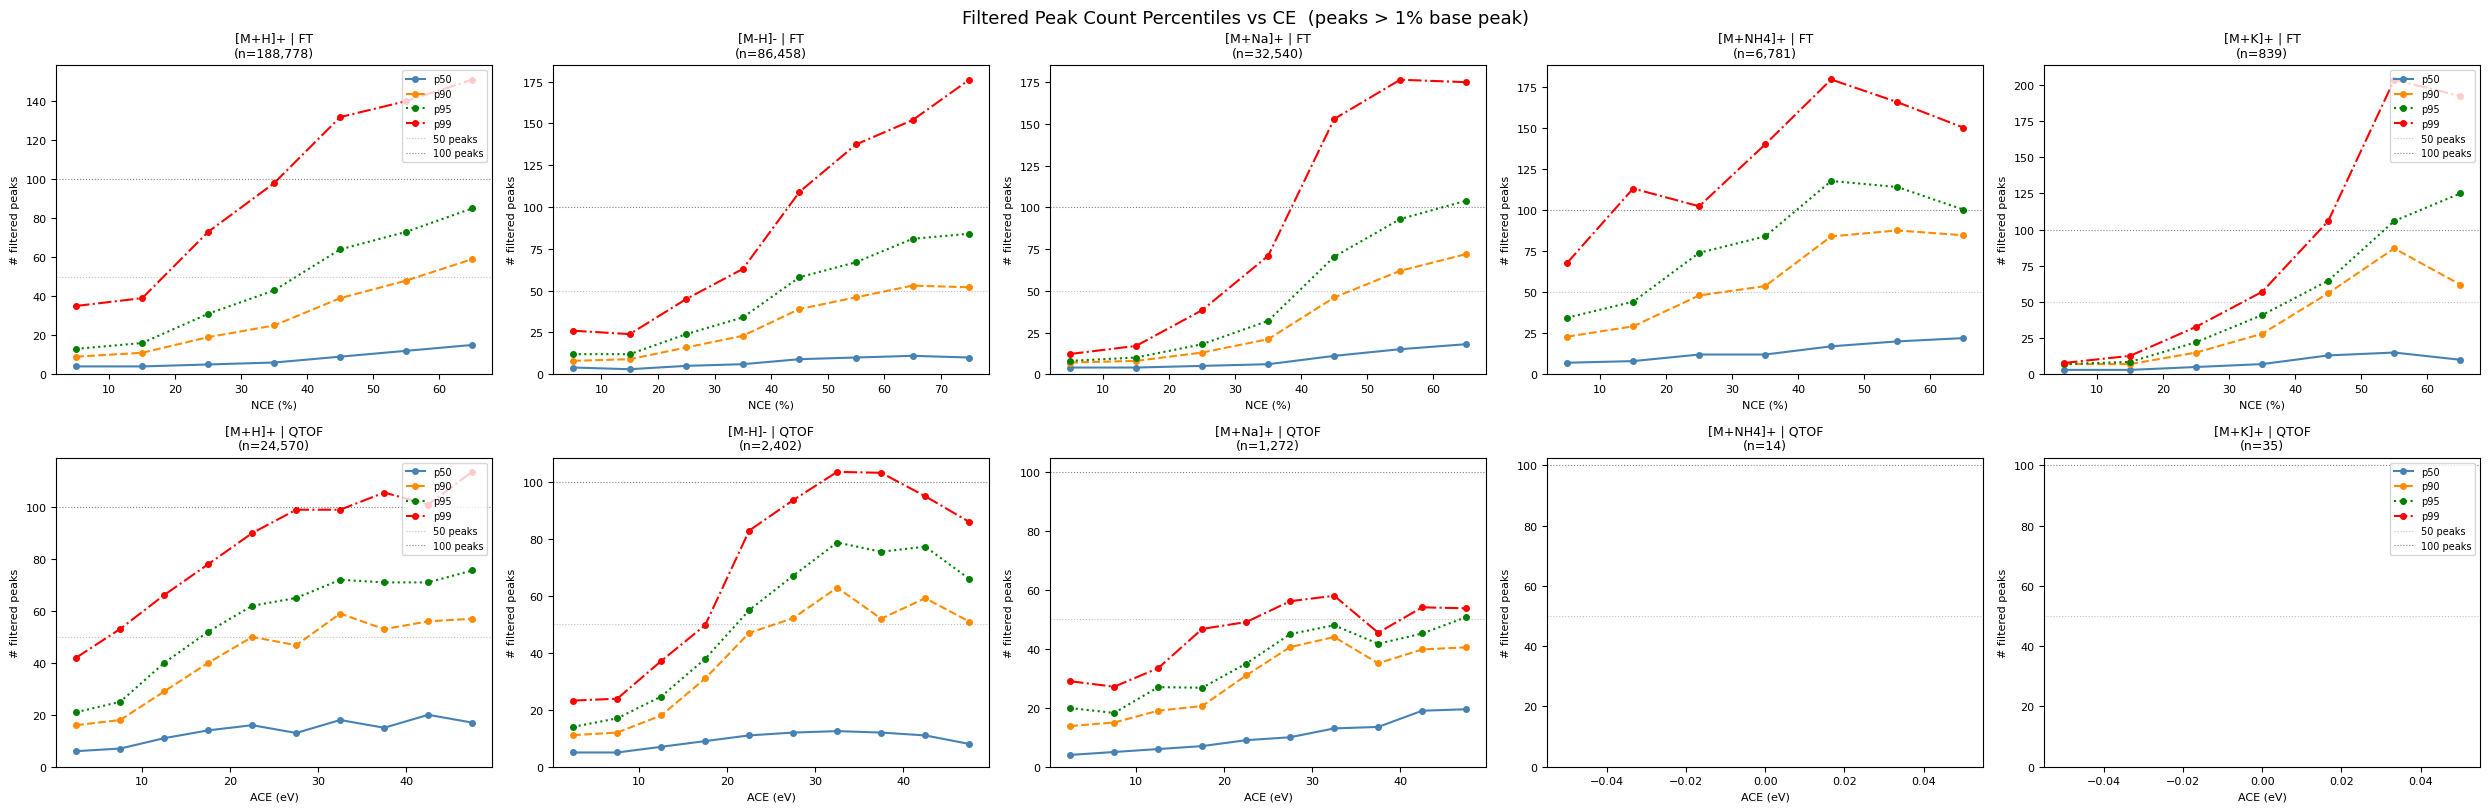

In [10]:
# Visualize filtered peak count percentiles vs CE, per adduct × inst type
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}
target_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+K]+']
percentile_cols = [('50%', 'steelblue', '-', 'p50'),
                   ('90%', 'darkorange', '--', 'p90'),
                   ('95%', 'green', ':', 'p95'),
                   ('99%', 'red', '-.', 'p99')]

ncols = len(target_adducts)
nrows = len(inst_ce_cfg)
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4), squeeze=False)

for row, (inst_type, (ce_col, ce_label, bin_size, bin_starts)) in enumerate(inst_ce_cfg.items()):
    ce_bins = list(bin_starts)
    ce_bin_labels = [f"{b}-{b+bin_size}" for b in ce_bins[:-1]]
    ce_bin_centers = [b + bin_size / 2 for b in ce_bins[:-1]]

    for col, prec_type in enumerate(target_adducts):
        ax = axes[row, col]

        df_sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            [ce_col, 'filtered_num_peaks'],
        ].dropna(subset=[ce_col]).copy()

        if len(df_sub) == 0:
            ax.set_visible(False)
            continue

        df_sub['ce_bin_idx'] = df_sub[ce_col].apply(
            lambda v: int((v - ce_bins[0]) // bin_size)
        )
        df_sub = df_sub[df_sub['ce_bin_idx'].between(0, len(ce_bin_labels) - 1)]

        pct_data = {pct: [] for pct, *_ in percentile_cols}
        valid_centers = []
        for i, center in enumerate(ce_bin_centers):
            subset = df_sub.loc[df_sub['ce_bin_idx'] == i, 'filtered_num_peaks']
            if len(subset) < 10:
                continue
            desc = subset.describe(percentiles=[0.50, 0.90, 0.95, 0.99])
            for pct, *_ in percentile_cols:
                pct_data[pct].append(desc[pct])
            valid_centers.append(center)

        for pct, color, ls, label in percentile_cols:
            ax.plot(valid_centers, pct_data[pct], color=color, linestyle=ls,
                    marker='o', markersize=4, linewidth=1.5, label=label)

        ax.axhline(50, color='gray', linestyle=':', linewidth=0.8, alpha=0.5, label='50 peaks')
        ax.axhline(100, color='black', linestyle=':', linewidth=0.8, alpha=0.5, label='100 peaks')
        ax.set_title(f"{prec_type} | {inst_type}\n(n={len(df_sub):,})", fontsize=9)
        ax.set_xlabel(ce_label, fontsize=8)
        ax.set_ylabel('# filtered peaks', fontsize=8)
        ax.set_ylim(bottom=0)
        ax.tick_params(labelsize=8)
        if col == ncols - 1 or col == 0:
            ax.legend(fontsize=7, loc='upper right')

plt.tight_layout()
plt.suptitle('Filtered Peak Count Percentiles vs CE  (peaks > 1% base peak)',
             fontsize=13, y=1.01)
plt.show()


In [11]:
# Truncation rate (% spectra with >k peaks) per adduct × inst type after 1% relative filter
thresholds = [30, 50, 60, 80, 100]
target_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+K]+', '[M+NH4]+']

rows = []
for inst_type in ['FT', 'QTOF']:
    for prec_type in target_adducts:
        sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            'filtered_num_peaks'
        ]
        if len(sub) < 10:
            continue
        row = {'group': f'{prec_type} | {inst_type}', 'n': len(sub),
               'p50': sub.quantile(0.50), 'p90': sub.quantile(0.90),
               'p95': sub.quantile(0.95), 'p99': sub.quantile(0.99)}
        for k in thresholds:
            row[f'trunc@{k}'] = round(100 * (sub > k).mean(), 1)
        rows.append(row)

trunc_df = pd.DataFrame(rows).set_index('group')
trunc_df.style.format('{:.1f}').background_gradient(
    subset=[f'trunc@{k}' for k in thresholds], cmap='Reds', vmin=0, vmax=30
)


,n,p50,p90,p95,p99,trunc@30,trunc@50,trunc@60,trunc@80,trunc@100
group,,,,,,,,,,
[M+H]+ | FT,188778.0,7.0,31.0,51.0,112.0,10.2,5.2,3.9,2.3,1.3
[M-H]- | FT,86458.0,6.0,29.0,45.0,97.0,9.2,4.0,2.8,1.6,0.9
[M+Na]+ | FT,32540.0,7.0,30.0,48.0,115.0,9.6,4.6,3.4,2.0,1.3
[M+K]+ | FT,839.0,6.0,28.0,45.2,93.7,9.1,4.2,2.6,1.3,1.0
[M+NH4]+ | FT,6781.0,11.0,57.0,84.0,139.2,19.6,11.4,9.2,5.7,3.2
[M+H]+ | QTOF,24570.0,12.0,45.0,59.0,90.3,18.8,7.7,4.7,1.6,0.6
[M-H]- | QTOF,2402.0,8.0,41.0,55.0,89.0,15.1,6.8,3.9,1.6,0.4
[M+Na]+ | QTOF,1272.0,7.0,29.0,38.0,50.3,8.6,1.0,0.3,0.0,0.0
[M+K]+ | QTOF,35.0,8.0,19.4,26.0,26.7,0.0,0.0,0.0,0.0,0.0


In [12]:
# Intensity loss (%) at each top-k threshold — per adduct × inst type, broken down by CE bin
import numpy as np

def intensity_loss_at_k(peaks, k):
    if not peaks:
        return 0.0
    max_int = max(i for _, i in peaks)
    if max_int <= 0:
        return 0.0
    filtered = sorted([i for _, i in peaks if i > 0.01 * max_int], reverse=True)
    total = sum(filtered)
    if total == 0:
        return 0.0
    return 1.0 - sum(filtered[:k]) / total

inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}
thresholds = [30, 50, 60, 80, 100]
target_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+K]+', '[M+NH4]+']

mean_rows, p95_rows = [], []

for inst_type, (ce_col, ce_label, bin_size, bin_starts) in inst_ce_cfg.items():
    ce_bins = list(bin_starts)
    ce_bin_labels = [f'{b}-{b+bin_size}' for b in ce_bins[:-1]]

    for prec_type in target_adducts:
        df_sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
        ].copy()
        if len(df_sub) < 10:
            continue

        # pre-compute losses for all thresholds once
        for k in thresholds:
            df_sub[f'loss_{k}'] = df_sub['peaks'].apply(lambda p, k=k: intensity_loss_at_k(p, k)) * 100

        # ALL CE row
        label = f'{prec_type} | {inst_type} | ALL {ce_label}'
        mean_row = {'group': label, 'n': len(df_sub)}
        p95_row  = {'group': label, 'n': len(df_sub)}
        for k in thresholds:
            mean_row[f'mean@{k}'] = round(df_sub[f'loss_{k}'].mean(), 2)
            p95_row[f'p95@{k}']   = round(df_sub[f'loss_{k}'].quantile(0.95), 2)
        mean_rows.append(mean_row)
        p95_rows.append(p95_row)

        # per CE bin
        df_sub['ce_bin_idx'] = df_sub[ce_col].apply(
            lambda v: int((v - ce_bins[0]) // bin_size)
            if pd.notna(v) and 0 <= int((v - ce_bins[0]) // bin_size) < len(ce_bin_labels) else -1
        )
        for i, lbl in enumerate(ce_bin_labels):
            grp = df_sub[df_sub['ce_bin_idx'] == i]
            if len(grp) < 10:
                continue
            label = f'{prec_type} | {inst_type} | {ce_label}={lbl}'
            mean_row = {'group': label, 'n': len(grp)}
            p95_row  = {'group': label, 'n': len(grp)}
            for k in thresholds:
                mean_row[f'mean@{k}'] = round(grp[f'loss_{k}'].mean(), 2)
                p95_row[f'p95@{k}']   = round(grp[f'loss_{k}'].quantile(0.95), 2)
            mean_rows.append(mean_row)
            p95_rows.append(p95_row)

mean_loss_df = pd.DataFrame(mean_rows).set_index('group')
p95_loss_df  = pd.DataFrame(p95_rows).set_index('group')

mean_cols = [f'mean@{k}' for k in thresholds]
p95_cols  = [f'p95@{k}'  for k in thresholds]

print('=== Mean intensity loss (%) ===')
display(mean_loss_df.style
    .format('{:.2f}')
    .background_gradient(subset=mean_cols, cmap='Reds', vmin=0, vmax=15)
    .set_table_styles([{'selector': 'th', 'props': [('font-size', '11px')]}]))

print('=== p95 intensity loss (%) ===')
display(p95_loss_df.style
    .format('{:.2f}')
    .background_gradient(subset=p95_cols, cmap='Reds', vmin=0, vmax=40)
    .set_table_styles([{'selector': 'th', 'props': [('font-size', '11px')]}]))


=== Mean intensity loss (%) ===


,n,mean@30,mean@50,mean@60,mean@80,mean@100
group,,,,,,
[M+H]+ | FT | ALL NCE (%),188778.00,1.16,0.46,0.31,0.15,0.08
[M+H]+ | FT | NCE (%)=0-10,13930.00,0.12,0.04,0.03,0.01,0.01
[M+H]+ | FT | NCE (%)=10-20,18876.00,0.12,0.03,0.02,0.01,0.00
[M+H]+ | FT | NCE (%)=20-30,31799.00,0.48,0.16,0.10,0.04,0.02
[M+H]+ | FT | NCE (%)=30-40,51269.00,0.90,0.35,0.23,0.11,0.05
[M+H]+ | FT | NCE (%)=40-50,32119.00,1.70,0.71,0.49,0.24,0.13
[M+H]+ | FT | NCE (%)=50-60,20372.00,2.08,0.83,0.56,0.27,0.14
[M+H]+ | FT | NCE (%)=60-70,20413.00,2.79,1.13,0.77,0.38,0.20
[M-H]- | FT | ALL NCE (%),86458.00,0.84,0.32,0.22,0.11,0.06


=== p95 intensity loss (%) ===


,n,p95@30,p95@50,p95@60,p95@80,p95@100
group,,,,,,
[M+H]+ | FT | ALL NCE (%),188778.00,7.58,0.29,0.00,0.00,0.00
[M+H]+ | FT | NCE (%)=0-10,13930.00,0.00,0.00,0.00,0.00,0.00
[M+H]+ | FT | NCE (%)=10-20,18876.00,0.00,0.00,0.00,0.00,0.00
[M+H]+ | FT | NCE (%)=20-30,31799.00,0.20,0.00,0.00,0.00,0.00
[M+H]+ | FT | NCE (%)=30-40,51269.00,4.44,0.00,0.00,0.00,0.00
[M+H]+ | FT | NCE (%)=40-50,32119.00,12.50,3.33,0.84,0.00,0.00
[M+H]+ | FT | NCE (%)=50-60,20372.00,15.29,5.10,2.32,0.00,0.00
[M+H]+ | FT | NCE (%)=60-70,20413.00,19.08,8.08,4.72,0.58,0.00
[M-H]- | FT | ALL NCE (%),86458.00,4.69,0.00,0.00,0.00,0.00


Computing intensity losses for all filter methods...
Done. (343,689 spectra)


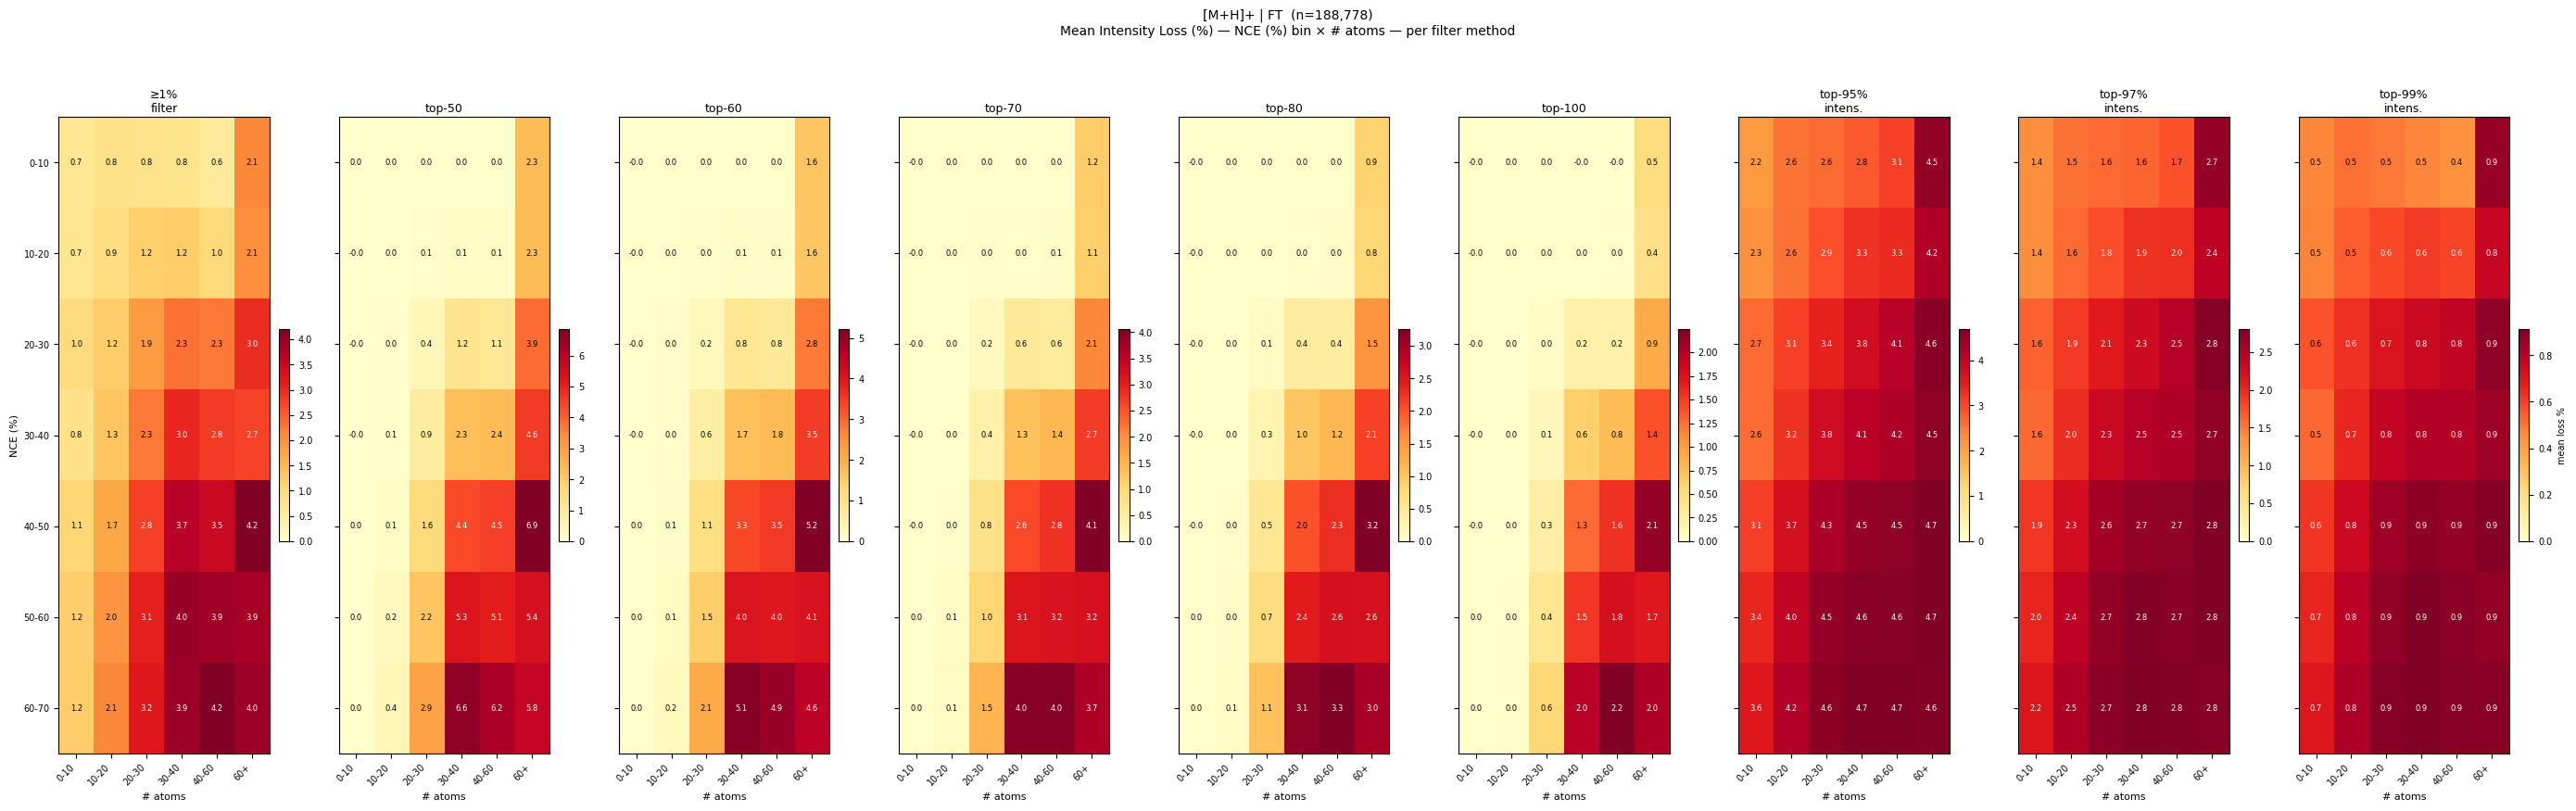

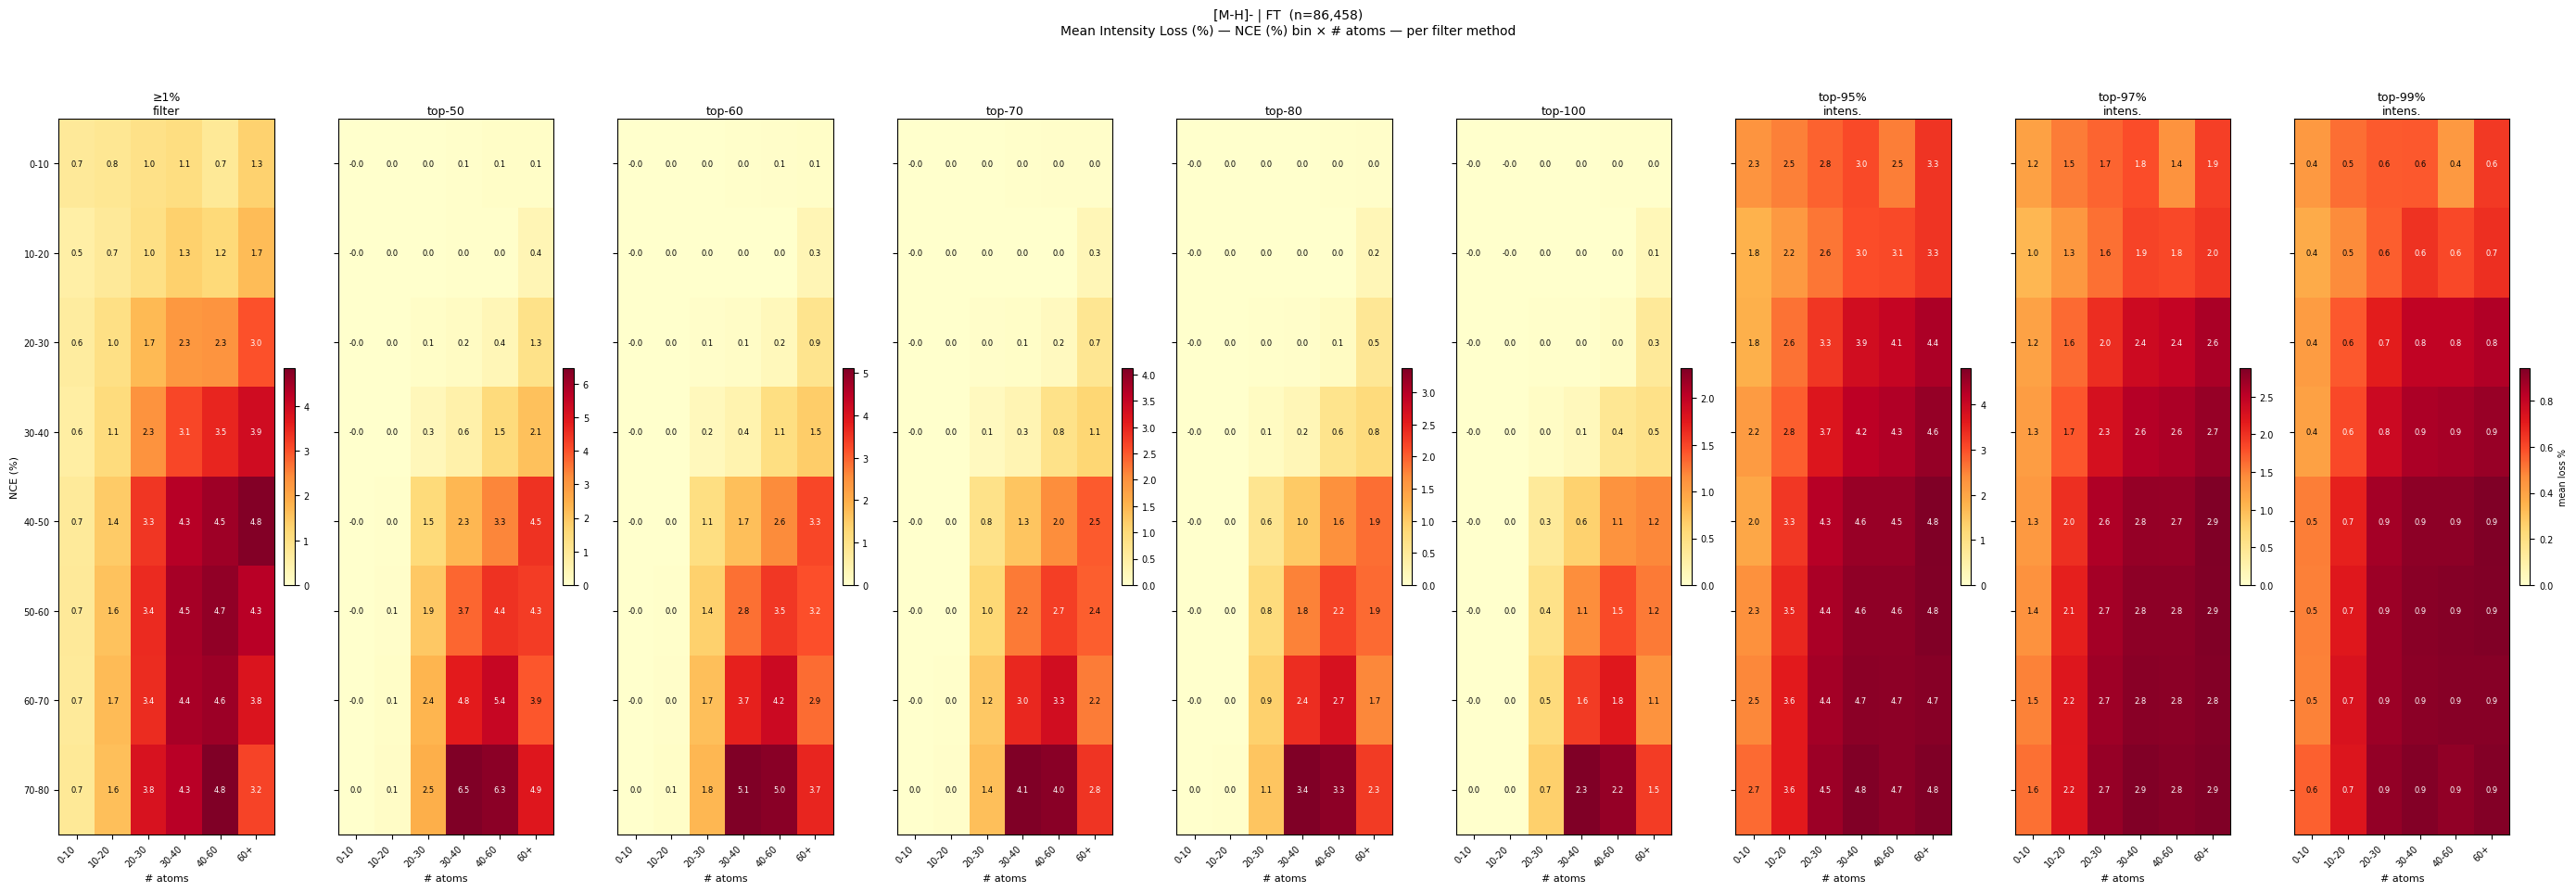

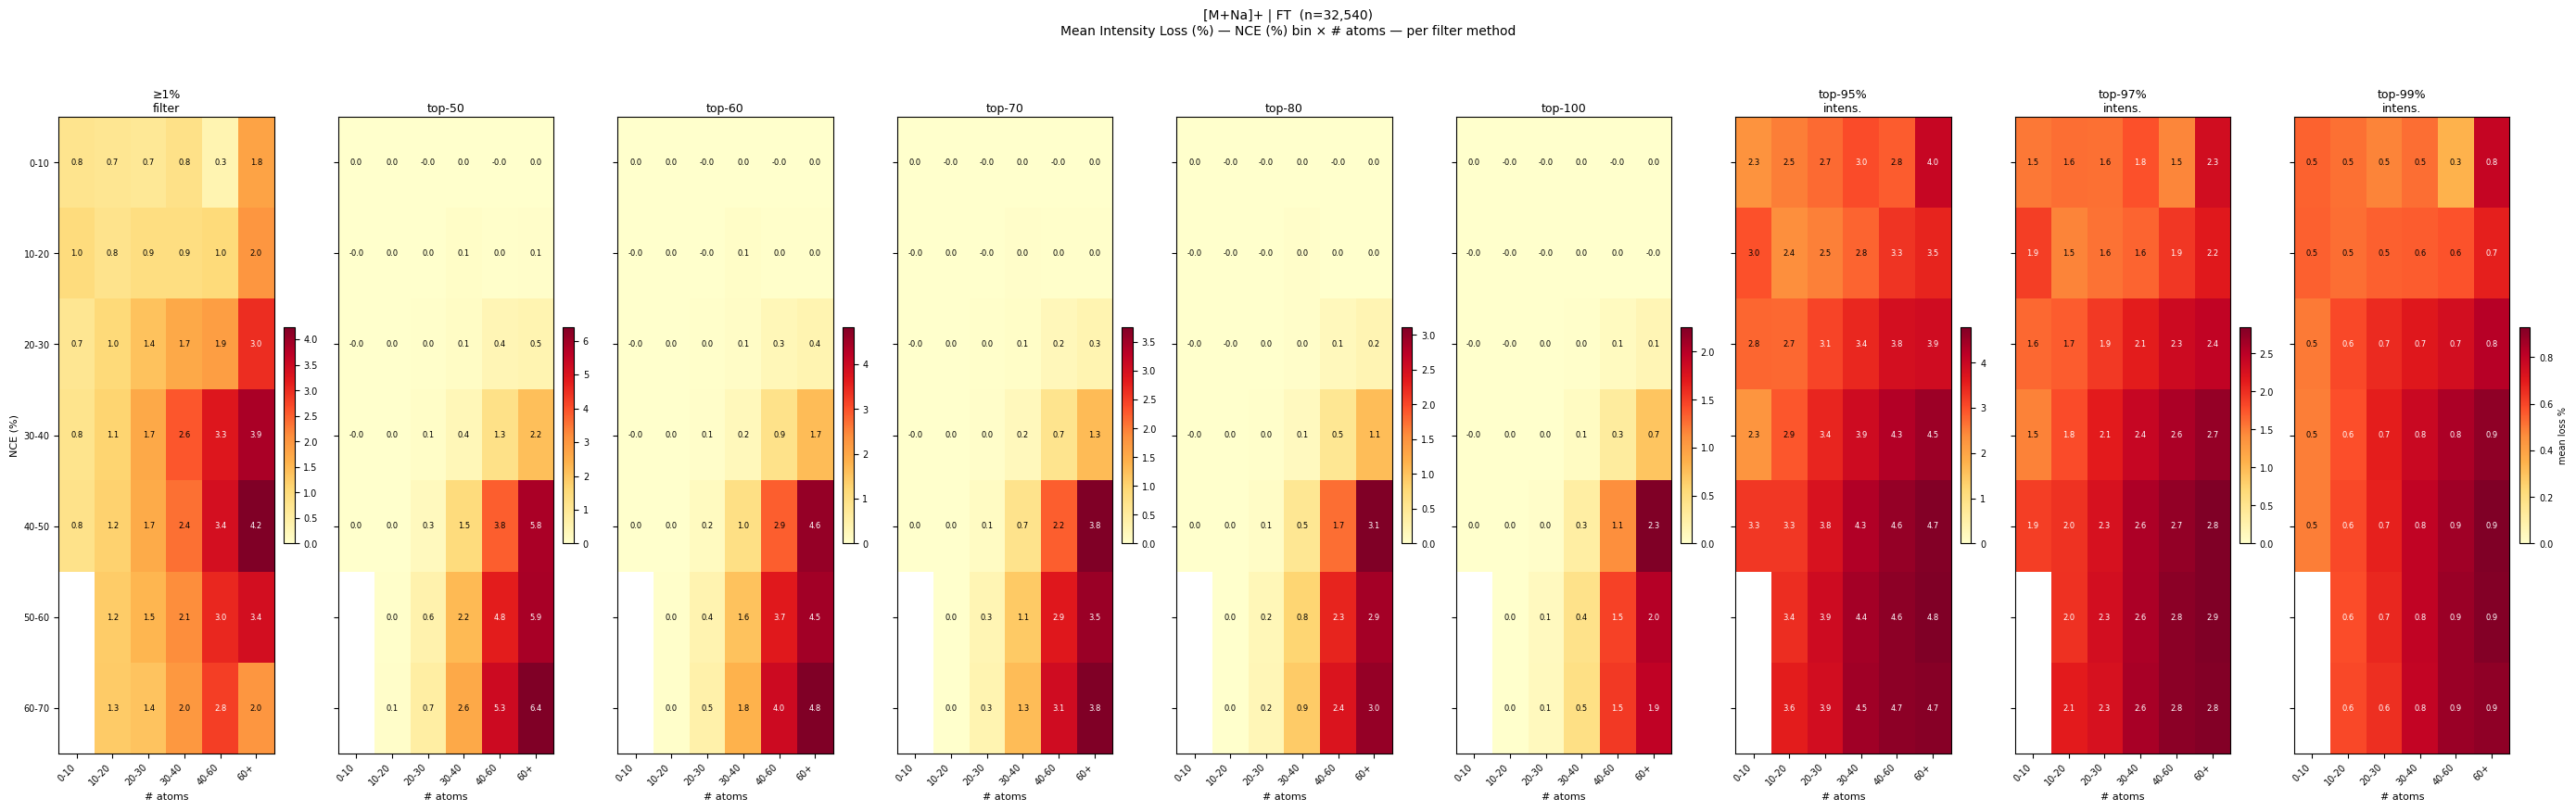

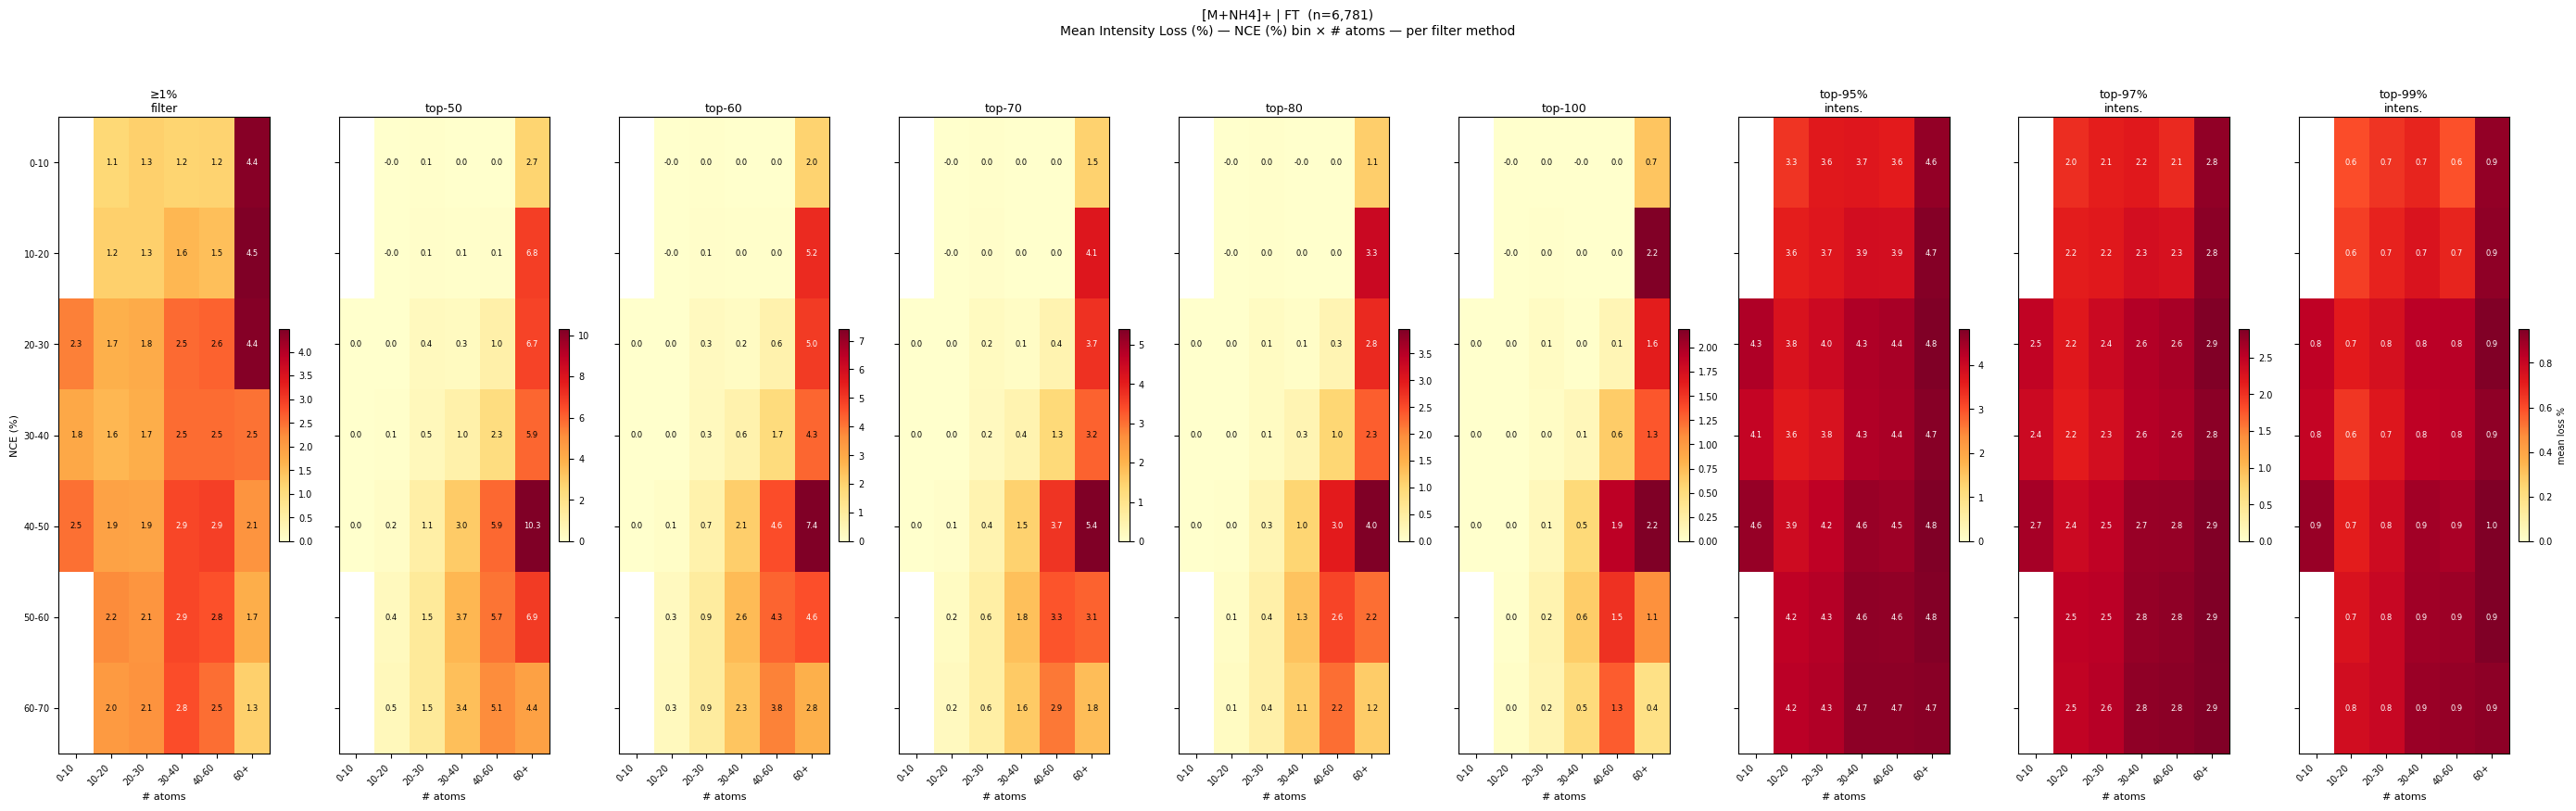

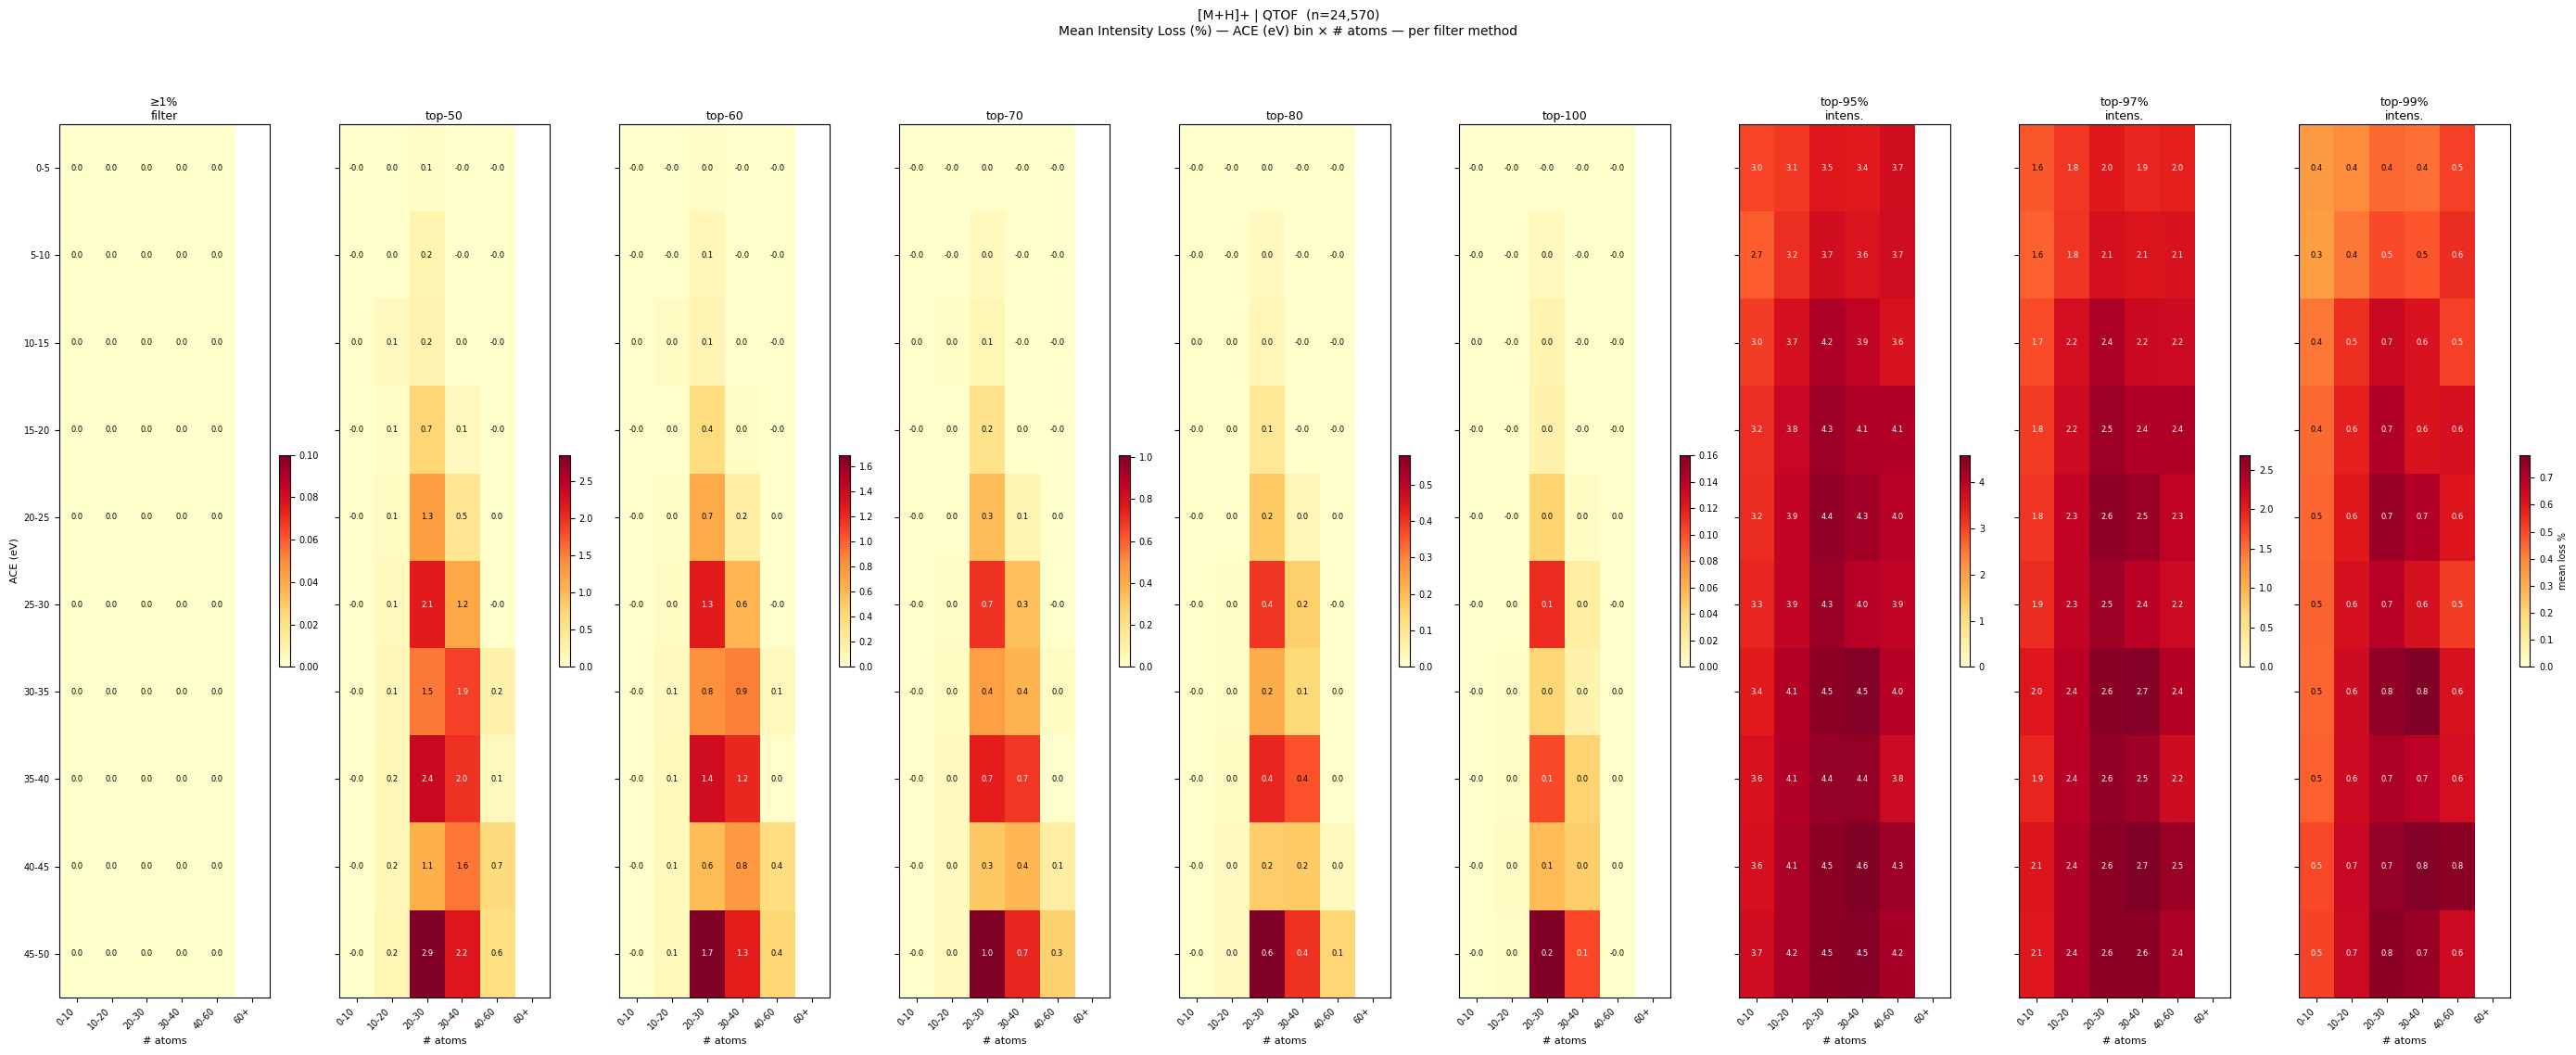

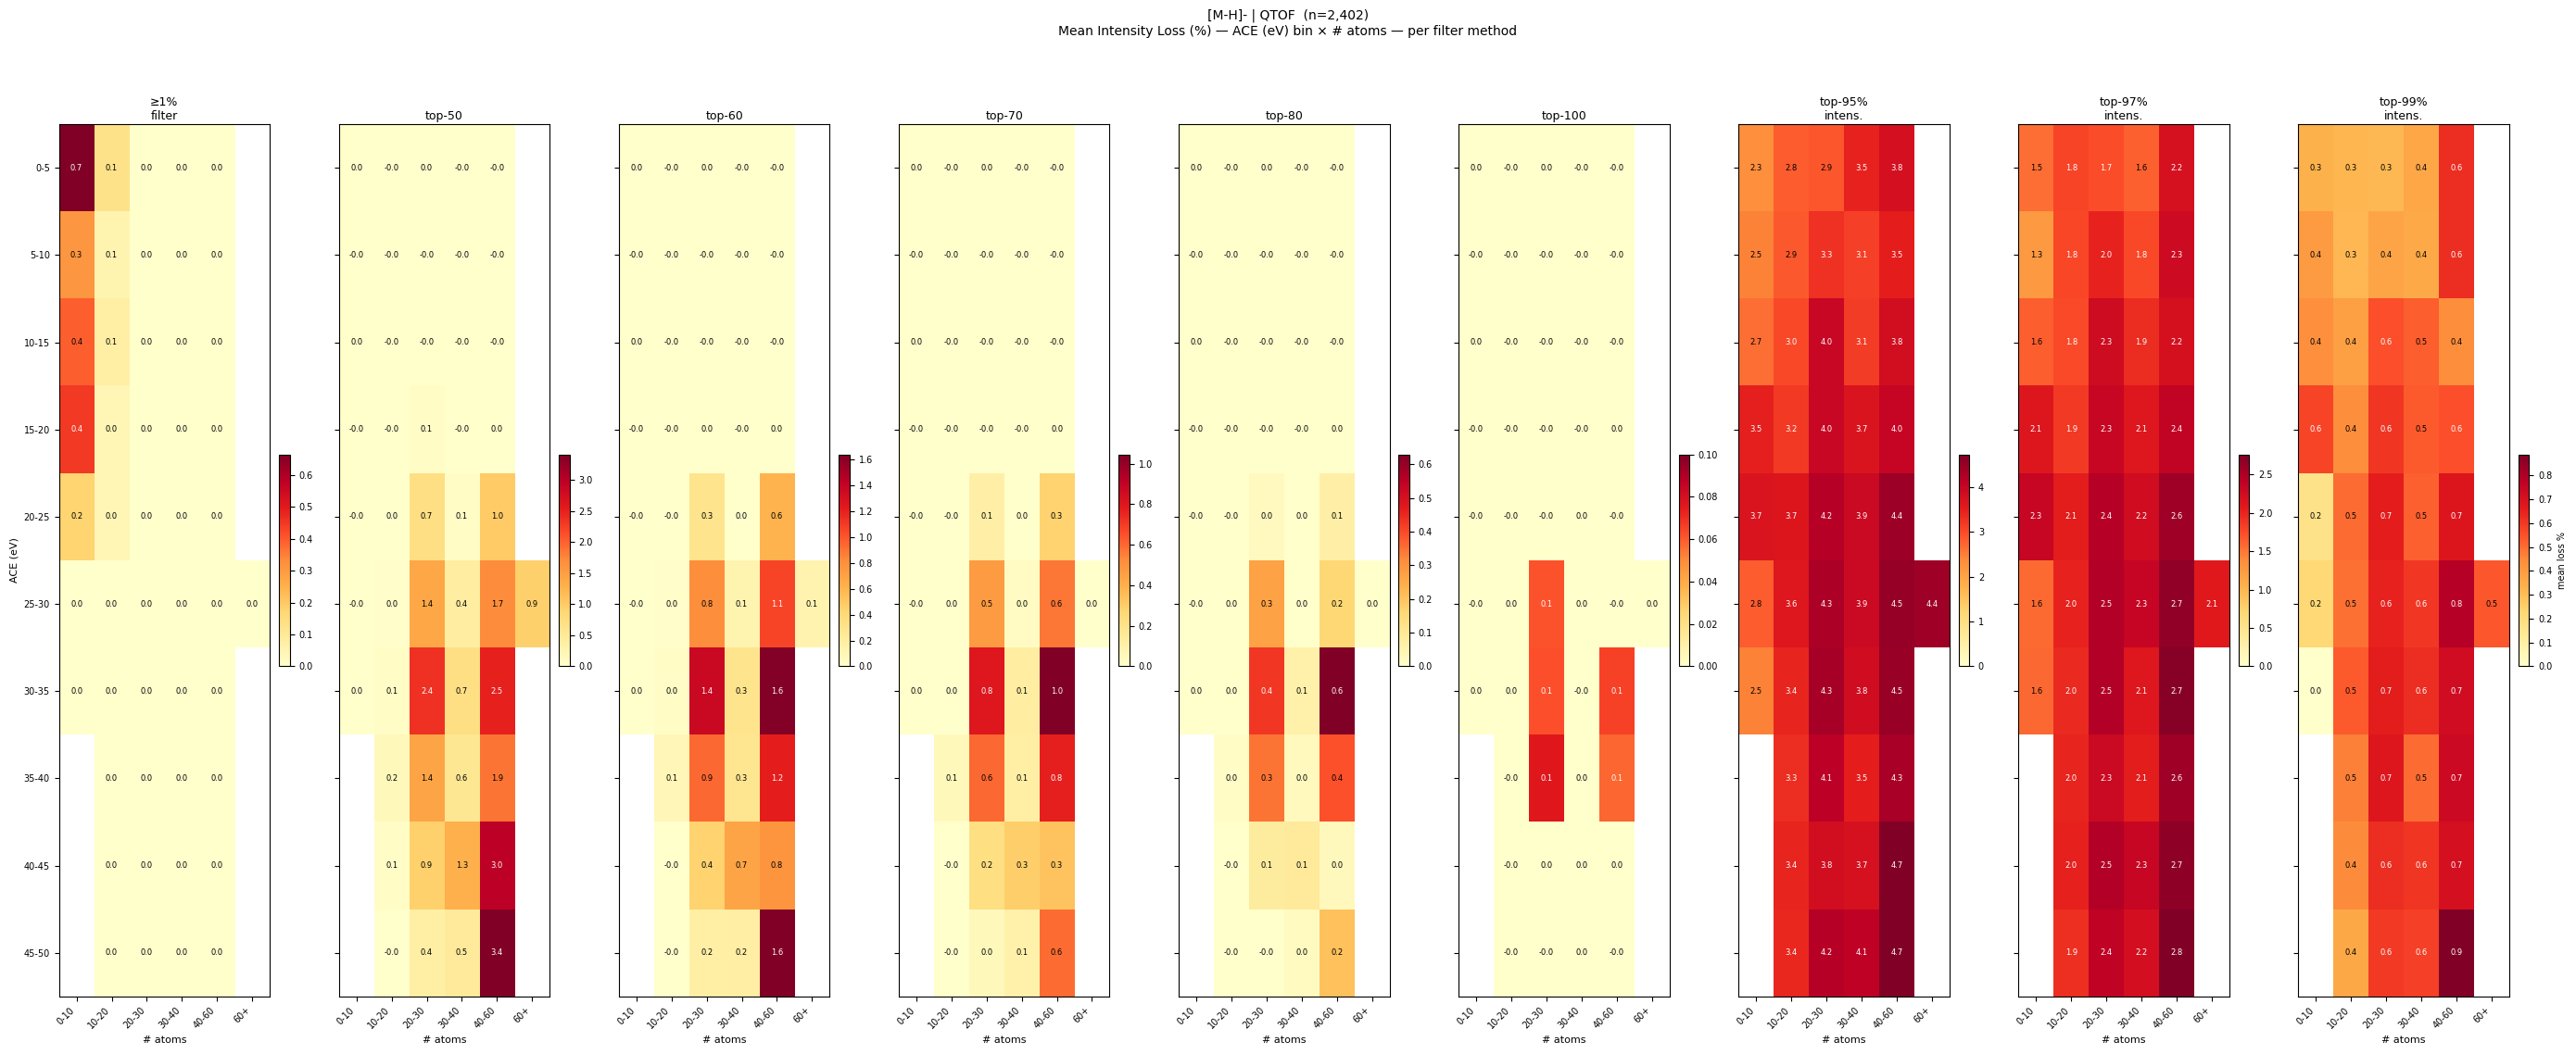

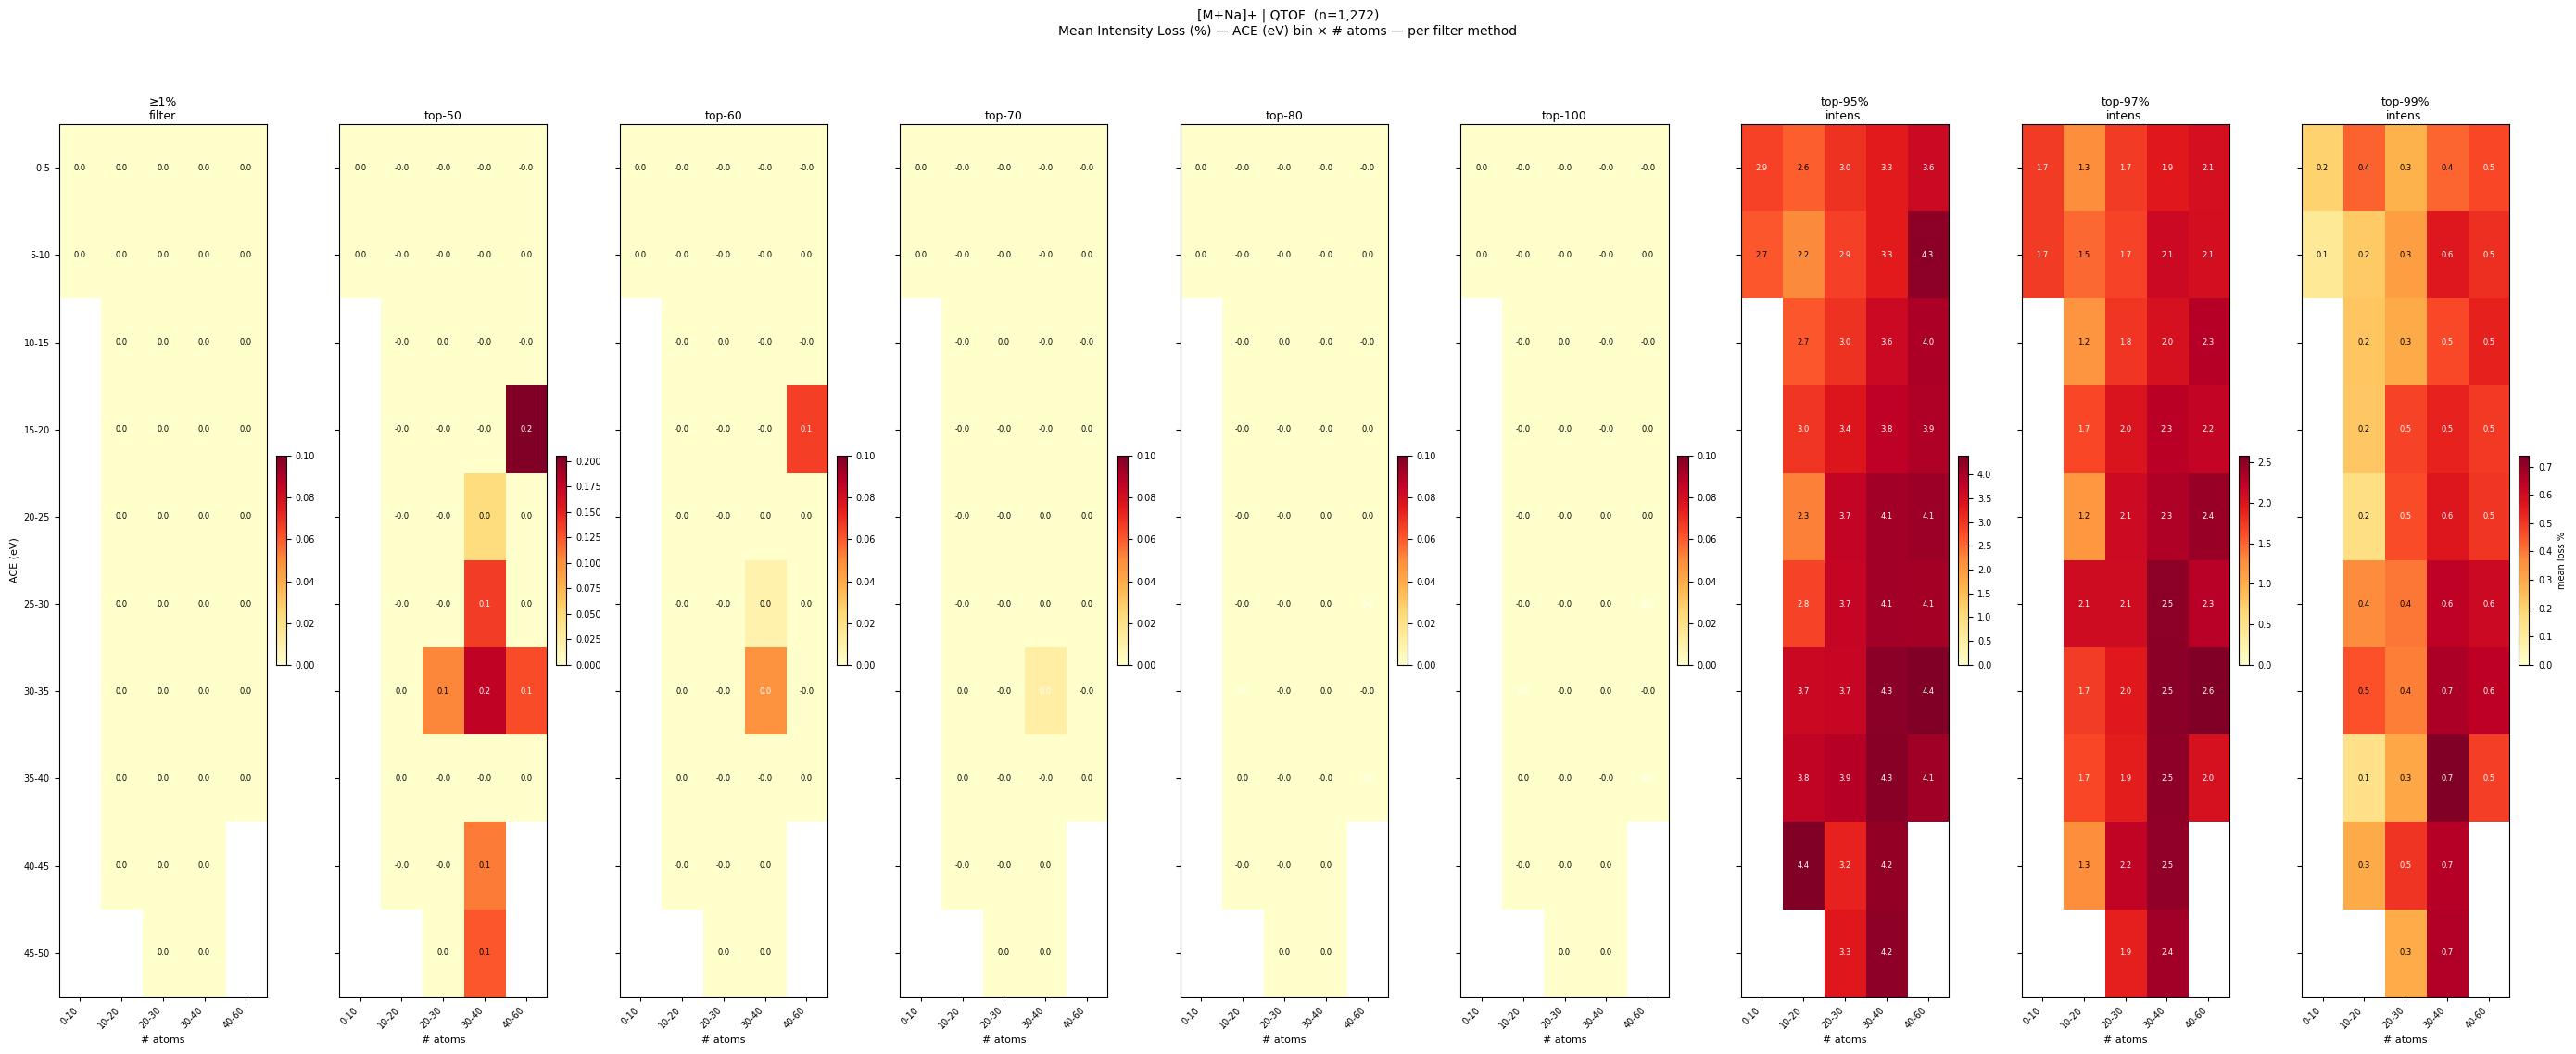

In [13]:
# Average intensity loss % by filter method — grid: CE bin (y) × # atoms bin (x)
# Filter methods: ≥1% base peak | top-50/60/70/80/100 peaks | top-95/97/99% cumulative intensity
# One figure per adduct × inst_type; each figure has one heatmap column per method
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILTER_DEFS = [
    ('pct1',     '≥1%\nfilter'),
    ('top50',    'top-50'),
    ('top60',    'top-60'),
    ('top70',    'top-70'),
    ('top80',    'top-80'),
    ('top100',   'top-100'),
    ('top95pct', 'top-95%\nintens.'),
    ('top97pct', 'top-97%\nintens.'),
    ('top99pct', 'top-99%\nintens.'),
]


def _compute_losses(peaks):
    """Return intensity loss (%) relative to raw spectrum total for each filter method."""
    if not peaks:
        return {m: 0.0 for m, _ in FILTER_DEFS}
    intens = np.array([i for _, i in peaks], dtype=float)
    total = intens.sum()
    if total == 0:
        return {m: 0.0 for m, _ in FILTER_DEFS}
    sorted_desc = np.sort(intens)[::-1]
    cumsum = np.cumsum(sorted_desc)
    n = len(cumsum)
    results = {}
    # ≥1% base peak filter
    results['pct1'] = (1.0 - intens[intens > 0.01 * intens.max()].sum() / total) * 100
    # top-k: loss relative to full raw spectrum
    for k in [50, 60, 70, 80, 100]:
        results[f'top{k}'] = (1.0 - cumsum[min(k, n) - 1] / total) * 100
    # top-X% intensity: keep minimum peaks covering ≥X% of total
    for pct in [95, 97, 99]:
        idx = min(int(np.searchsorted(cumsum, pct / 100.0 * total)), n - 1)
        results[f'top{pct}pct'] = (1.0 - cumsum[idx] / total) * 100
    return results


# Pre-compute losses (cached in df columns); recompute if any column is missing
_LOSS_COLS = {m: f'_loss_{m}' for m, _ in FILTER_DEFS}
if any(col not in nist_spectra_df.columns for col in _LOSS_COLS.values()):
    print('Computing intensity losses for all filter methods...')
    _all_losses = nist_spectra_df['peaks'].apply(_compute_losses)
    for m, col in _LOSS_COLS.items():
        nist_spectra_df[col] = _all_losses.apply(lambda d, m=m: d[m])
    print(f'Done. ({len(nist_spectra_df):,} spectra)')

# Atom bins
_ATOM_EDGES  = [0, 10, 20, 30, 40, 60, np.inf]
_ATOM_LABELS = ['0-10', '10-20', '20-30', '30-40', '40-60', '60+']
if '_atom_bin' not in nist_spectra_df.columns:
    nist_spectra_df['_atom_bin'] = pd.cut(
        nist_spectra_df['num_atoms'], bins=_ATOM_EDGES,
        labels=_ATOM_LABELS, right=False
    )

_INST_CE = {
    'FT':   ('nce', 'NCE (%)',  10, list(range(0, 80, 10))),
    'QTOF': ('ace', 'ACE (eV)',  5, list(range(0, 55,  5))),
}
_TARGET_ADDUCTS = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+']
_N = len(FILTER_DEFS)

for inst_type, (ce_col, ce_label, bsz, bstarts) in _INST_CE.items():
    ce_edges  = bstarts + [bstarts[-1] + bsz]
    ce_labels = [f'{b}-{b+bsz}' for b in bstarts]

    for prec_type in _TARGET_ADDUCTS:
        sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type)
        ].copy()
        if len(sub) < 50:
            continue

        sub['_ce_bin'] = pd.cut(sub[ce_col], bins=ce_edges, labels=ce_labels, right=False)
        sub = sub.dropna(subset=['_ce_bin'])

        active_ce  = [l for l in ce_labels   if (sub['_ce_bin']   == l).sum() >= 10]
        active_atm = [l for l in _ATOM_LABELS if (sub['_atom_bin'] == l).sum() >= 5]
        if not active_ce or not active_atm:
            continue

        # Build one heatmap array per filter method via groupby
        heats, vmaxes = [], []
        for method, _ in FILTER_DEFS:
            pivot = (
                sub.groupby(['_ce_bin', '_atom_bin'], observed=True)[_LOSS_COLS[method]]
                .agg(lambda x: x.mean() if len(x) >= 5 else np.nan)
                .unstack('_atom_bin')
                .reindex(index=active_ce, columns=active_atm)
            )
            arr = pivot.values.astype(float)
            heats.append(arr)
            vmaxes.append(float(np.nanmax(arr)) if not np.all(np.isnan(arr)) else 1.0)

        fig, axes = plt.subplots(
            1, _N,
            figsize=(_N * 3.1, max(4.0, len(active_ce) * 0.85 + 2.5)),
            squeeze=False,
        )

        for idx, (heat, vmax, (method, mlabel)) in enumerate(zip(heats, vmaxes, FILTER_DEFS)):
            ax = axes[0, idx]
            im = ax.imshow(heat, aspect='auto', vmin=0, vmax=max(vmax, 0.1),
                           cmap='YlOrRd', origin='upper')
            ax.set_xticks(range(len(active_atm)))
            ax.set_xticklabels(active_atm, rotation=45, ha='right', fontsize=7)
            ax.set_yticks(range(len(active_ce)))
            ax.set_yticklabels(active_ce if idx == 0 else [], fontsize=7)
            ax.set_title(mlabel, fontsize=9, pad=4)
            ax.set_xlabel('# atoms', fontsize=8)
            if idx == 0:
                ax.set_ylabel(ce_label, fontsize=8)

            # Annotate each cell with the mean loss value
            for i in range(len(active_ce)):
                for j in range(len(active_atm)):
                    v = heat[i, j]
                    if not np.isnan(v):
                        ax.text(j, i, f'{v:.1f}',
                                ha='center', va='center', fontsize=6,
                                color='white' if v > 0.62 * vmax else 'black')

            cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            cbar.ax.tick_params(labelsize=7)
            if idx == _N - 1:
                cbar.set_label('mean loss %', fontsize=7)

        plt.suptitle(
            f'{prec_type} | {inst_type}  (n={len(sub):,})\n'
            f'Mean Intensity Loss (%) — {ce_label} bin × # atoms — per filter method',
            fontsize=10, y=1.03,
        )
        plt.tight_layout()
        plt.show()


In [ ]:
# Peak count distribution after each filter method
# For each adduct × inst_type: 3×3 grid of step-histograms (one per method)
# Lines colored by CE bin; quantile markers (p95/p99) shown per CE bin
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_PKCOUNT_COLS = {m: f'_pkcount_{m}' for m, _ in FILTER_DEFS}


def _compute_peak_counts(peaks):
    """Return number of peaks retained by each filter method."""
    if not peaks:
        return {m: 0 for m, _ in FILTER_DEFS}
    intens = np.array([i for _, i in peaks], dtype=float)
    n_raw = len(intens)
    total = intens.sum()
    if total == 0:
        return {m: 0 for m, _ in FILTER_DEFS}
    sorted_desc = np.sort(intens)[::-1]
    cumsum = np.cumsum(sorted_desc)
    results = {}
    results['pct1'] = int((intens > 0.01 * intens.max()).sum())
    for k in [50, 60, 70, 80, 100]:
        results[f'top{k}'] = min(k, n_raw)
    for pct in [95, 97, 99]:
        idx = min(int(np.searchsorted(cumsum, pct / 100.0 * total)), n_raw - 1)
        results[f'top{pct}pct'] = idx + 1
    return results


if any(col not in nist_spectra_df.columns for col in _PKCOUNT_COLS.values()):
    print('Computing peak counts after each filter method...')
    _all_pk = nist_spectra_df['peaks'].apply(_compute_peak_counts)
    for m, col in _PKCOUNT_COLS.items():
        nist_spectra_df[col] = _all_pk.apply(lambda d, m=m: d[m])
    print(f'Done. ({len(nist_spectra_df):,} spectra)')

_NCOLS_D = 3
_NROWS_D = math.ceil(_N / _NCOLS_D)
_QUANTILES   = [0.95, 0.99]
_Q_LABELS    = ['p95', 'p99']
_Q_LINESTYLE = [':', '-.']
_Q_ALPHA     = [0.75, 0.90]

for inst_type, (ce_col, ce_label, bsz, bstarts) in _INST_CE.items():
    ce_edges  = bstarts + [bstarts[-1] + bsz]
    ce_labels = [f'{b}-{b+bsz}' for b in bstarts]
    palette   = plt.cm.viridis(np.linspace(0.1, 0.9, len(ce_labels)))
    ce_color  = {l: palette[i] for i, l in enumerate(ce_labels)}

    for prec_type in _TARGET_ADDUCTS:
        sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type)
        ].copy()
        if len(sub) < 50:
            continue

        sub['_ce_bin'] = pd.cut(sub[ce_col], bins=ce_edges, labels=ce_labels, right=False)
        sub = sub.dropna(subset=['_ce_bin'])
        active_ce = [l for l in ce_labels if (sub['_ce_bin'] == l).sum() >= 10]
        if not active_ce:
            continue

        fig, axes = plt.subplots(
            _NROWS_D, _NCOLS_D,
            figsize=(_NCOLS_D * 5, _NROWS_D * 3.8),
            squeeze=False,
        )

        x_max = 200
        bins = np.linspace(0, x_max, min(x_max, 100) + 1)

        for idx, (method, mlabel) in enumerate(FILTER_DEFS):
            ax = axes[idx // _NCOLS_D, idx % _NCOLS_D]
            col = _PKCOUNT_COLS[method]

            for ce_bin in active_ce:
                vals = sub.loc[sub['_ce_bin'] == ce_bin, col]
                color = ce_color[ce_bin]
                ax.hist(vals, bins=bins, density=True, histtype='step',
                        linewidth=1.3, color=color, alpha=0.9)

                for q, qls, qa in zip(_QUANTILES, _Q_LINESTYLE, _Q_ALPHA):
                    ax.axvline(vals.quantile(q), color=color, linewidth=0.8,
                               linestyle=qls, alpha=qa, ymax=0.25)

            for ref_k, ls in [(50, ':'), (100, '--')]:
                ax.axvline(ref_k, color='black', linewidth=0.7, linestyle=ls, alpha=0.35)

            ax.set_title(mlabel.replace('\n', ' '), fontsize=9)
            ax.set_xlabel('# peaks retained', fontsize=8)
            ax.set_ylabel('density', fontsize=8)
            ax.set_xlim(left=0, right=x_max)
            ax.tick_params(labelsize=7)

        for idx in range(_N, _NROWS_D * _NCOLS_D):
            axes[idx // _NCOLS_D, idx % _NCOLS_D].set_visible(False)

        ce_handles = [
            plt.Line2D([0], [0], color=ce_color[l], linewidth=1.5, label=l)
            for l in active_ce
        ]
        q_handles = [
            plt.Line2D([0], [0], color='gray', linewidth=0.9, linestyle=ls, alpha=qa, label=ql)
            for ql, ls, qa in zip(_Q_LABELS, _Q_LINESTYLE, _Q_ALPHA)
        ]
        fig.legend(handles=ce_handles + [plt.Line2D([], [], alpha=0)] + q_handles,
                   title=f'{ce_label} bins  /  quantiles',
                   bbox_to_anchor=(1.0, 0.5), loc='center left',
                   fontsize=7, title_fontsize=8)

        plt.suptitle(
            f'{prec_type} | {inst_type}  (n={len(sub):,})\n'
            f'# Peaks Retained — Distribution per Filter Method '
            f'(colored by {ce_label} bin; tick-marks = per-CE-bin p95/p99)',
            fontsize=10, y=1.02,
        )
        plt.tight_layout()
        plt.show()


In [ ]:
# Peak count distribution: combined ≥1% base-peak filter + top-80 cap
# One subplot per adduct × inst_type; lines colored by CE bin; p95/p99 markers per CE bin
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Combined count: apply pct1 first, then cap at 80
nist_spectra_df['_pkcount_pct1_top80'] = nist_spectra_df['_pkcount_pct1'].clip(upper=80)

_NCOLS = 4
_ADDUCTS_GRID = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+']
_INST_TYPES   = ['FT', 'QTOF']
_NROWS = len(_INST_TYPES)

_X_MAX = 200
_BINS  = np.linspace(0, _X_MAX, 101)
_QUANTILES   = [0.95, 0.99]
_Q_LABELS    = ['p95', 'p99']
_Q_LINESTYLE = [':', '-.']
_Q_ALPHA     = [0.75, 0.90]

fig, axes = plt.subplots(
    _NROWS, _NCOLS,
    figsize=(_NCOLS * 5, _NROWS * 3.8),
    squeeze=False,
)

for row, inst_type in enumerate(_INST_TYPES):
    ce_col, ce_label, bsz, bstarts = _INST_CE[inst_type]
    ce_edges  = bstarts + [bstarts[-1] + bsz]
    ce_labels = [f'{b}-{b+bsz}' for b in bstarts]
    palette   = plt.cm.viridis(np.linspace(0.1, 0.9, len(ce_labels)))
    ce_color  = {l: palette[i] for i, l in enumerate(ce_labels)}

    for col, prec_type in enumerate(_ADDUCTS_GRID):
        ax = axes[row, col]
        sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type)
        ].copy()

        if len(sub) < 50:
            ax.set_visible(False)
            continue

        sub['_ce_bin'] = pd.cut(sub[ce_col], bins=ce_edges, labels=ce_labels, right=False)
        sub = sub.dropna(subset=['_ce_bin'])
        active_ce = [l for l in ce_labels if (sub['_ce_bin'] == l).sum() >= 10]
        if not active_ce:
            ax.set_visible(False)
            continue

        for ce_bin in active_ce:
            vals = sub.loc[sub['_ce_bin'] == ce_bin, '_pkcount_pct1_top80']
            color = ce_color[ce_bin]
            ax.hist(vals, bins=_BINS, density=True, histtype='step',
                    linewidth=1.3, color=color, alpha=0.9, label=ce_bin)
            for q, qls, qa in zip(_QUANTILES, _Q_LINESTYLE, _Q_ALPHA):
                ax.axvline(vals.quantile(q), color=color, linewidth=0.8,
                           linestyle=qls, alpha=qa, ymax=0.25)

        for ref_k, ls in [(50, ':'), (80, '--')]:
            ax.axvline(ref_k, color='black', linewidth=0.7, linestyle=ls, alpha=0.35)

        ax.set_title(f'{prec_type} | {inst_type}  (n={len(sub):,})', fontsize=9)
        ax.set_xlabel('# peaks retained', fontsize=8)
        ax.set_ylabel('density', fontsize=8)
        ax.set_xlim(left=0, right=_X_MAX)
        ax.tick_params(labelsize=7)

        if col == _NCOLS - 1:
            ce_handles = [
                plt.Line2D([0], [0], color=ce_color[l], linewidth=1.5, label=l)
                for l in active_ce
            ]
            q_handles = [
                plt.Line2D([0], [0], color='gray', linewidth=0.9, linestyle=ls, alpha=qa, label=ql)
                for ql, ls, qa in zip(_Q_LABELS, _Q_LINESTYLE, _Q_ALPHA)
            ]
            ax.legend(handles=ce_handles + [plt.Line2D([], [], alpha=0)] + q_handles,
                      title=f'{ce_label}  /  quantiles',
                      bbox_to_anchor=(1.02, 1), loc='upper left',
                      fontsize=6, title_fontsize=7)

plt.suptitle(
    '# Peaks Retained — ≥1% base-peak filter + top-80 cap\n'
    '(colored by CE bin; dashed marks = p95/p99 per CE bin; '
    'vertical lines: 50 peaks · · ·  80 peaks - - -)',
    fontsize=10, y=1.02,
)
plt.tight_layout()
plt.show()


## Noise filter recommendation

All losses below are relative to the **raw spectrum total intensity** (NIST20-HR, NCE ≤ 70 for FT / ACE ≤ 50 for QTOF).

### Key numbers — [M+H]+ FT (n = 188 k, dominant subset)

| Filter | mean loss % | p95 loss % | p95 peak count |
|--------|-------------|------------|----------------|
| ≥1% base peak | 1.84 | 5.71 | 51 |
| top-50 | 0.74 | 4.28 | 50 |
| **top-80** | **0.28** | **0.45** | **80** |
| top-100 | 0.13 | 0.09 | 100 |
| top-95% intens. | 3.56 | 4.95 | 48 |
| top-97% intens. | 2.17 | 2.97 | 57 |
| top-99% intens. | 0.72 | 0.99 | 73 |

By NCE bin (mean loss %, [M+H]+ FT):

| NCE | ≥1% | top-50 | top-80 | top-95% | top-97% | top-99% |
|-----|-----|--------|--------|---------|---------|---------|
| 0–20 | 1.09 | 0.11 | 0.03 | 2.86 | 1.74 | 0.57 |
| 20–40 | 1.82 | 0.64 | 0.24 | 3.53 | 2.15 | 0.72 |
| 40–70 | 2.49 | 1.42 | 0.54 | 4.19 | 2.53 | 0.83 |

---

### Recommendation: **≥1% base peak filter + top-80 hard cap**

**≥1% filter** is the right *noise* filter. Any peak below 1 % of the dominant peak is instrument noise or a minor isotope artifact, not a genuine fragmentation signal. It costs ~1.8 % mean intensity loss and already cuts the typical spectrum to a median of 7 peaks.

**top-80 as a secondary cap** is nearly lossless on top of that (p95 loss only 0.45 %) and prevents the rare 100–400-peak spectra that appear at high CE / large molecules from inflating batch memory.  
top-50 is too aggressive at high CE (p95 loss 4.28 %); top-100 is fine but gives no meaningful cap for the worst-case spectra.

**Avoid the intensity-threshold filters (top-95 %/97 %/99 %) as a noise filter.** They back-fire on simple spectra: a low-CE spectrum where one peak dominates 95 % of intensity gets reduced to 1 peak, losing 5 % — worse than the 1 % filter and discarding real fragments. Their mean loss (3.56 % for top-95 %) is higher than every hard-cutoff method because of this sparse-spectrum artifact.

**Final choice:** `peaks > 1% of base peak` → keep top 80 by intensity.


In [16]:
# Filter comparison summary — mean & p95 intensity loss (vs raw total) and p95 peak count
# Uses _loss_* / _pkcount_* columns cached by the two cells above
import pandas as pd
import numpy as np

FILTER_SUMMARY = [
    ('_loss_pct1',     '_pkcount_pct1',     '≥1% filter'),
    ('_loss_top50',    '_pkcount_top50',    'top-50'),
    ('_loss_top80',    '_pkcount_top80',    'top-80'),
    ('_loss_top100',   '_pkcount_top100',   'top-100'),
    ('_loss_top95pct', '_pkcount_top95pct', 'top-95% intens.'),
    ('_loss_top97pct', '_pkcount_top97pct', 'top-97% intens.'),
    ('_loss_top99pct', '_pkcount_top99pct', 'top-99% intens.'),
]

# --- Per-adduct × inst summary ---
for prec_type, inst_type in [('[M+H]+', 'FT'), ('[M-H]-', 'FT'), ('[M+H]+', 'QTOF'), ('[M-H]-', 'QTOF')]:
    sub = nist_spectra_df[
        (nist_spectra_df['prec_type'] == prec_type) &
        (nist_spectra_df['inst_type'] == inst_type)
    ]
    if len(sub) < 50:
        continue
    rows = []
    for lc, pc, lbl in FILTER_SUMMARY:
        rows.append({
            'method':      lbl,
            'mean loss %': round(sub[lc].mean(), 2),
            'p95 loss %':  round(sub[lc].quantile(0.95), 2),
            'p95 peaks':   int(round(sub[pc].quantile(0.95))),
        })
    tbl = pd.DataFrame(rows).set_index('method')
    print(f'\n{prec_type} | {inst_type}  (n={len(sub):,})')
    display(
        tbl.style
        .background_gradient(subset=['mean loss %', 'p95 loss %'], cmap='YlOrRd', vmin=0, vmax=8)
        .background_gradient(subset=['p95 peaks'],                  cmap='Blues',  vmin=0, vmax=100)
        .format({'mean loss %': '{:.2f}', 'p95 loss %': '{:.2f}', 'p95 peaks': '{:d}'})
    )

# --- CE-bin breakdown for [M+H]+ FT ---
print('\n[M+H]+ | FT — mean loss % by NCE bin')
sub_ft = nist_spectra_df[
    (nist_spectra_df['prec_type'] == '[M+H]+') &
    (nist_spectra_df['inst_type'] == 'FT')
].copy()
sub_ft['_nce_bin'] = pd.cut(
    sub_ft['nce'], bins=[0, 20, 40, 70], labels=['NCE 0–20', 'NCE 20–40', 'NCE 40–70']
)
loss_cols = [lc for lc, _, _ in FILTER_SUMMARY]
col_labels = [lb for _, _, lb in FILTER_SUMMARY]
pivot = sub_ft.groupby('_nce_bin', observed=True)[loss_cols].mean().round(2)
pivot.columns = col_labels
display(
    pivot.style
    .background_gradient(cmap='YlOrRd', vmin=0, vmax=6)
    .format('{:.2f}')
)



[M+H]+ | FT  (n=188,778)


,mean loss %,p95 loss %,p95 peaks
method,,,
≥1% filter,1.84,5.71,51
top-50,0.74,4.28,50
top-80,0.28,0.45,80
top-100,0.16,0.00,89
top-95% intens.,3.56,4.95,48
top-97% intens.,2.17,2.97,57
top-99% intens.,0.72,0.99,73



[M-H]- | FT  (n=86,458)


,mean loss %,p95 loss %,p95 peaks
method,,,
≥1% filter,2.01,6.32,45
top-50,0.69,3.95,50
top-80,0.29,0.70,80
top-100,0.18,0.00,97
top-95% intens.,3.44,4.95,45
top-97% intens.,2.10,2.97,56
top-99% intens.,0.71,0.99,76



[M+H]+ | QTOF  (n=24,570)


,mean loss %,p95 loss %,p95 peaks
method,,,
≥1% filter,0.00,0.00,59
top-50,0.46,2.45,50
top-80,0.07,0.00,59
top-100,0.02,0.00,59
top-95% intens.,3.90,4.94,43
top-97% intens.,2.27,2.95,49
top-99% intens.,0.60,0.97,56



[M-H]- | QTOF  (n=2,402)


,mean loss %,p95 loss %,p95 peaks
method,,,
≥1% filter,0.03,0.00,55
top-50,0.38,1.53,50
top-80,0.05,0.00,55
top-100,0.01,0.00,55
top-95% intens.,3.57,4.93,40
top-97% intens.,2.09,2.95,46
top-99% intens.,0.50,0.97,52



[M+H]+ | FT — mean loss % by NCE bin


,≥1% filter,top-50,top-80,top-100,top-95% intens.,top-97% intens.,top-99% intens.
_nce_bin,,,,,,,
NCE 0–20,1.09,0.11,0.03,0.01,2.86,1.74,0.57
NCE 20–40,1.82,0.64,0.24,0.13,3.53,2.15,0.72
NCE 40–70,2.49,1.42,0.54,0.31,4.19,2.53,0.83
